# EventLens: Full Reproducible Pipeline

## Project purpose

EventLens is a prototype of a source-replaceable portfolio intelligence system.

The full product vision is an AI-assisted agent connected to authorised external
sources such as LSEG, Bloomberg, Reuters, FactSet, company filings, regulatory
announcements or internal research feeds.

The agent would:

1. retrieve financial news and events;
2. classify and normalise the information;
3. link events to affected portfolio holdings;
4. compare events with investment-thesis risks;
5. estimate abnormal market reactions;
6. calculate portfolio impact;
7. prioritise alerts for the portfolio manager.

## Reproducible prototype

This notebook demonstrates the analytical pipeline using:

- a theoretical 15-stock portfolio;
- market data retrieved with Yahoo Finance;
- the ACWI ETF as a transparent MSCI ACWI proxy;
- prices and FX rates converted into GBP;
- a market model estimated over a 252-trading-day window;
- a three-day post-event window;
- a frozen snapshot of historical events verified against official company sources;
- investment-thesis fields and keyword matching;
- transparent z-score-based alerts;
- SQLite storage.

The event records used in this reproducible run are not generated or
invented by the notebook. They are loaded from a frozen snapshot containing
historical events verified against official company investor-relations,
regulatory or corporate-news pages.

The notebook does not claim to retrieve live news. In the production version,
the event-ingestion layer would be connected to an authorised provider such as
LSEG or Bloomberg, or to approved company and regulatory feeds.

For reproducibility, the notebook uses a frozen verified snapshot. This ensures
that the results remain stable when the notebook is rerun.

When an official source provides only a publication date and not an exact
publication time, the event is stored as date-only. No publication time is
artificially invented.

## Methodological limitations

The ACWI ETF is used as a broad global-market proxy. The demonstration
portfolio is an equal-weighted 15-stock portfolio, so the comparison measures
relative performance against the global equity opportunity set rather than
replicating the benchmark.

The abnormal-return analysis uses a simplified market model and does not
establish causality. Different markets also have different closing times, so
same-day comparisons may not perfectly align information arrival and trading.

The keyword-based thesis matching is a transparent baseline for a future NLP
or LLM classification layer.

The system is intended for monitoring and prioritisation, not for automatic
investment advice.

In [21]:
# Core imports

from pathlib import Path
import re
import sqlite3
import warnings

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

print("Imports completed successfully.")
print("pandas version:", pd.__version__)
print("yfinance version:", yf.__version__)

Imports completed successfully.
pandas version: 2.2.2
yfinance version: 1.8.0


In [22]:
# Pipeline configuration

from pathlib import Path

# Market-data period
MARKET_START_DATE = "2021-01-01"

# Fixed cut-off date for reproducibility
AS_OF_DATE = pd.Timestamp("2026-11-10")

MARKET_END_DATE = (
    AS_OF_DATE + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

# Event period
EVENT_START_DATE = "2026-10-01"
EVENT_END_DATE = "2026-11-01"  # exclusive end date

# Base currency
BASE_CURRENCY = "GBP"

# Benchmark
BENCHMARK_SOURCE = "Yahoo Finance"
BENCHMARK_SYMBOL = "ACWI"
BENCHMARK_NAME = "MSCI ACWI proxy (ACWI ETF)"
BENCHMARK_CURRENCY = "USD"

# Event-study settings
ESTIMATION_WINDOW_DAYS = 252
EVENT_WINDOW_DAYS = 3
MIN_ESTIMATION_OBS = 120

# Relevance and alert settings
MIN_RELEVANCE_SCORE = 0.50
WATCH_Z_THRESHOLD = 1.50
ALERT_Z_THRESHOLD = 2.00
MIN_RESIDUAL_STD = 0.0001

# Event source configuration
# The notebook uses a frozen snapshot of historically verified events.
# No GDELT request and no live news retrieval are performed here.
EVENT_SOURCE_MODE = "verified_official_snapshot"

# Project folders
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
FIGURES_DIR = OUTPUT_DIR / "figures"

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# Frozen event snapshot
EVENT_SNAPSHOT_PATH = DATA_DIR / "events_snapshot.csv"

# Database for the verified-source version
DB_PATH = Path("eventlens_full_pipeline_verified.db")


def display_from_one(dataframe):
    """Display a DataFrame with visible row numbers starting from 1."""

    output = dataframe.copy()

    output.index = pd.RangeIndex(
        start=1,
        stop=len(output) + 1,
        name="row_id",
    )

    return output


print("Configuration loaded successfully.")
print(
    "Market period:",
    MARKET_START_DATE,
    "to",
    AS_OF_DATE.strftime("%Y-%m-%d"),
)
print(
    "Event period:",
    EVENT_START_DATE,
    "to",
    EVENT_END_DATE,
)
print("Base currency:", BASE_CURRENCY)
print("Benchmark:", BENCHMARK_NAME)
print("Event source mode:", EVENT_SOURCE_MODE)
print("Event snapshot:", EVENT_SNAPSHOT_PATH)
print("Database:", DB_PATH)

Configuration loaded successfully.
Market period: 2021-01-01 to 2026-11-10
Event period: 2026-10-01 to 2026-11-01
Base currency: GBP
Benchmark: MSCI ACWI proxy (ACWI ETF)
Event source mode: verified_official_snapshot
Event snapshot: data/events_snapshot.csv
Database: eventlens_full_pipeline_verified.db


In [23]:
# Demonstration portfolio and investment-thesis context

portfolio_data = [
    {
        "ticker": "DELL.N",
        "company_name": "Dell Technologies",
        "region": "US",
        "country": "United States",
        "sector": "Information Technology",
        "bucket": "AI Infrastructure",
        "currency": "USD",
        "yahoo_symbol": "DELL",
        "main_driver": "AI server demand",
        "thesis_risk": "Hyperscaler capex cuts",
        "risk_keywords": "capex, AI servers, guidance",
        "event_trigger": "Guidance cut",
    },
    {
        "ticker": "NOKIA.HE",
        "company_name": "Nokia",
        "region": "Europe",
        "country": "Finland",
        "sector": "Information Technology",
        "bucket": "AI Infrastructure",
        "currency": "EUR",
        "yahoo_symbol": "NOKIA.HE",
        "main_driver": "AI data-centre networking",
        "thesis_risk": "Weak telecom capex",
        "risk_keywords": "network orders, telecom capex, guidance",
        "event_trigger": "Network infrastructure orders fall",
    },
    {
        "ticker": "000660.KS",
        "company_name": "SK Hynix",
        "region": "Asia-Pacific",
        "country": "South Korea",
        "sector": "Information Technology",
        "bucket": "AI Infrastructure",
        "currency": "KRW",
        "yahoo_symbol": "000660.KS",
        "main_driver": "High-bandwidth memory pricing",
        "thesis_risk": "Memory price fall or export restrictions",
        "risk_keywords": "HBM, memory prices, export rules",
        "event_trigger": "HBM prices fall",
    },
    {
        "ticker": "CVX.N",
        "company_name": "Chevron",
        "region": "US",
        "country": "United States",
        "sector": "Energy",
        "bucket": "Energy and Resources",
        "currency": "USD",
        "yahoo_symbol": "CVX",
        "main_driver": "Oil price and Middle East supply",
        "thesis_risk": "Oil price decline",
        "risk_keywords": "Brent, Iran, oil supply",
        "event_trigger": "Brent falls significantly",
    },
    {
        "ticker": "EQNR.OL",
        "company_name": "Equinor",
        "region": "Europe",
        "country": "Norway",
        "sector": "Energy",
        "bucket": "Energy and Resources",
        "currency": "NOK",
        "yahoo_symbol": "EQNR.OL",
        "main_driver": "European gas prices",
        "thesis_risk": "Gas price collapse",
        "risk_keywords": "TTF gas, gas prices, tax",
        "event_trigger": "TTF gas price falls",
    },
    {
        "ticker": "RELI.NS",
        "company_name": "Reliance Industries",
        "region": "Asia-Pacific",
        "country": "India",
        "sector": "Energy",
        "bucket": "Energy and Resources",
        "currency": "INR",
        "yahoo_symbol": "RELIANCE.NS",
        "main_driver": "Refining, telecom and retail growth",
        "thesis_risk": "Refining margin squeeze",
        "risk_keywords": "refining margins, Jio, India policy",
        "event_trigger": "Refining margin declines",
    },
    {
        "ticker": "CPRT.O",
        "company_name": "Copart",
        "region": "US",
        "country": "United States",
        "sector": "Industrials",
        "bucket": "Quality and Pricing Power",
        "currency": "USD",
        "yahoo_symbol": "CPRT",
        "main_driver": "Used-car salvage auctions",
        "thesis_risk": "Used-car price decline",
        "risk_keywords": "used-car prices, salvage, insurance",
        "event_trigger": "Used-car index declines",
    },
    {
        "ticker": "SCHN.PA",
        "company_name": "Schneider Electric",
        "region": "Europe",
        "country": "France",
        "sector": "Industrials",
        "bucket": "AI Infrastructure",
        "currency": "EUR",
        "yahoo_symbol": "SU.PA",
        "main_driver": "Data-centre power and cooling demand",
        "thesis_risk": "Data-centre delays",
        "risk_keywords": "data centres, cooling, grid permits",
        "event_trigger": "Data-centre project cancelled",
    },
    {
        "ticker": "LULU.O",
        "company_name": "Lululemon",
        "region": "US",
        "country": "Canada",
        "sector": "Consumer Discretionary",
        "bucket": "Quality and Pricing Power",
        "currency": "USD",
        "yahoo_symbol": "LULU",
        "main_driver": "Premium brand and pricing power",
        "thesis_risk": "US consumer slowdown",
        "risk_keywords": "same-store sales, tariffs, demand",
        "event_trigger": "Guidance cut",
    },
    {
        "ticker": "ADSGn.DE",
        "company_name": "Adidas",
        "region": "Europe",
        "country": "Germany",
        "sector": "Consumer Discretionary",
        "bucket": "Quality and Pricing Power",
        "currency": "EUR",
        "yahoo_symbol": "ADS.DE",
        "main_driver": "Brand momentum and pricing",
        "thesis_risk": "Tariffs and demand slowdown",
        "risk_keywords": "tariffs, Asian production, guidance",
        "event_trigger": "New tariff or guidance cut",
    },
    {
        "ticker": "ISP.MI",
        "company_name": "Intesa Sanpaolo",
        "region": "Europe",
        "country": "Italy",
        "sector": "Financials",
        "bucket": "Financials",
        "currency": "EUR",
        "yahoo_symbol": "ISP.MI",
        "main_driver": "ECB rates and lending income",
        "thesis_risk": "ECB rate cuts or spread widening",
        "risk_keywords": "ECB, BTP-Bund spread, rates",
        "event_trigger": "BTP-Bund spread increases",
    },
    {
        "ticker": "DBSM.SI",
        "company_name": "DBS Group",
        "region": "Asia-Pacific",
        "country": "Singapore",
        "sector": "Financials",
        "bucket": "Financials",
        "currency": "SGD",
        "yahoo_symbol": "D05.SI",
        "main_driver": "Asian rates and credit quality",
        "thesis_risk": "Rate cuts and credit losses",
        "risk_keywords": "NIM, rates, Asian credit",
        "event_trigger": "Net interest margin guidance cut",
    },
    {
        "ticker": "HSY.N",
        "company_name": "Hershey",
        "region": "US",
        "country": "United States",
        "sector": "Consumer Staples",
        "bucket": "Defensives",
        "currency": "USD",
        "yahoo_symbol": "HSY",
        "main_driver": "Strong brands and pricing power",
        "thesis_risk": "Cocoa price spike",
        "risk_keywords": "cocoa, sugar, volumes",
        "event_trigger": "Cocoa price rises significantly",
    },
    {
        "ticker": "HLN.L",
        "company_name": "Haleon",
        "region": "Europe",
        "country": "United Kingdom",
        "sector": "Consumer Staples",
        "bucket": "Defensives",
        "currency": "GBP",
        "yahoo_symbol": "HLN.L",
        "main_driver": "Consumer health demand",
        "thesis_risk": "Litigation or volume decline",
        "risk_keywords": "litigation, GBP, organic growth",
        "event_trigger": "Organic growth guidance cut",
    },
    {
        "ticker": "7974.T",
        "company_name": "Nintendo",
        "region": "Asia-Pacific",
        "country": "Japan",
        "sector": "Communication Services",
        "bucket": "Quality and Pricing Power",
        "currency": "JPY",
        "yahoo_symbol": "7974.T",
        "main_driver": "Console cycle and game franchises",
        "thesis_risk": "Weak hardware sales or delays",
        "risk_keywords": "Switch, games, JPY",
        "event_trigger": "Sales forecast cut",
    },
]

portfolio = pd.DataFrame(portfolio_data)

portfolio.insert(
    0,
    "instrument_id",
    range(1, len(portfolio) + 1)
)

portfolio["weight"] = 1.0 / len(portfolio)
portfolio["benchmark"] = BENCHMARK_NAME

assert len(portfolio) == 15
assert portfolio["ticker"].is_unique
assert portfolio["yahoo_symbol"].is_unique
assert np.isclose(portfolio["weight"].sum(), 1.0)
assert portfolio["risk_keywords"].notna().all()

portfolio.index = pd.RangeIndex(
    start=1,
    stop=len(portfolio) + 1,
    name="row_id"
)

portfolio.to_csv(
    DATA_DIR / "portfolio_metadata.csv",
    index=False
)

print("Portfolio and thesis context created.")
print("Number of holdings:", len(portfolio))
print("Total portfolio weight:", round(portfolio["weight"].sum(), 6))

display(display_from_one(portfolio))

Portfolio and thesis context created.
Number of holdings: 15
Total portfolio weight: 1.0


,instrument_id,ticker,company_name,region,country,sector,bucket,currency,yahoo_symbol,main_driver,thesis_risk,risk_keywords,event_trigger,weight,benchmark
row_id,,,,,,,,,,,,,,,
1,1,DELL.N,Dell Technologies,US,United States,Information Technology,AI Infrastructure,USD,DELL,AI server demand,Hyperscaler capex cuts,"capex, AI servers, guidance",Guidance cut,0.066667,MSCI ACWI proxy (ACWI ETF)
2,2,NOKIA.HE,Nokia,Europe,Finland,Information Technology,AI Infrastructure,EUR,NOKIA.HE,AI data-centre networking,Weak telecom capex,"network orders, telecom capex, guidance",Network infrastructure orders fall,0.066667,MSCI ACWI proxy (ACWI ETF)
3,3,000660.KS,SK Hynix,Asia-Pacific,South Korea,Information Technology,AI Infrastructure,KRW,000660.KS,High-bandwidth memory pricing,Memory price fall or export restrictions,"HBM, memory prices, export rules",HBM prices fall,0.066667,MSCI ACWI proxy (ACWI ETF)
4,4,CVX.N,Chevron,US,United States,Energy,Energy and Resources,USD,CVX,Oil price and Middle East supply,Oil price decline,"Brent, Iran, oil supply",Brent falls significantly,0.066667,MSCI ACWI proxy (ACWI ETF)
5,5,EQNR.OL,Equinor,Europe,Norway,Energy,Energy and Resources,NOK,EQNR.OL,European gas prices,Gas price collapse,"TTF gas, gas prices, tax",TTF gas price falls,0.066667,MSCI ACWI proxy (ACWI ETF)
6,6,RELI.NS,Reliance Industries,Asia-Pacific,India,Energy,Energy and Resources,INR,RELIANCE.NS,"Refining, telecom and retail growth",Refining margin squeeze,"refining margins, Jio, India policy",Refining margin declines,0.066667,MSCI ACWI proxy (ACWI ETF)
7,7,CPRT.O,Copart,US,United States,Industrials,Quality and Pricing Power,USD,CPRT,Used-car salvage auctions,Used-car price decline,"used-car prices, salvage, insurance",Used-car index declines,0.066667,MSCI ACWI proxy (ACWI ETF)
8,8,SCHN.PA,Schneider Electric,Europe,France,Industrials,AI Infrastructure,EUR,SU.PA,Data-centre power and cooling demand,Data-centre delays,"data centres, cooling, grid permits",Data-centre project cancelled,0.066667,MSCI ACWI proxy (ACWI ETF)
9,9,LULU.O,Lululemon,US,Canada,Consumer Discretionary,Quality and Pricing Power,USD,LULU,Premium brand and pricing power,US consumer slowdown,"same-store sales, tariffs, demand",Guidance cut,0.066667,MSCI ACWI proxy (ACWI ETF)


In [24]:
# SQLite database schema

PORTFOLIO_ID = "DEMO_15_STOCK"

# Close a previous connection if the cell is executed again
try:
    connection.close()
except NameError:
    pass

connection = sqlite3.connect(DB_PATH)
connection.execute("PRAGMA foreign_keys = ON")

connection.executescript(
    """
    CREATE TABLE IF NOT EXISTS instruments (
        instrument_id INTEGER PRIMARY KEY,
        ticker TEXT NOT NULL UNIQUE,
        company_name TEXT NOT NULL,
        region TEXT NOT NULL,
        country TEXT NOT NULL,
        sector TEXT NOT NULL,
        bucket TEXT NOT NULL,
        currency TEXT NOT NULL,
        yahoo_symbol TEXT NOT NULL UNIQUE
    );

    CREATE TABLE IF NOT EXISTS portfolio_positions (
        portfolio_id TEXT NOT NULL,
        instrument_id INTEGER NOT NULL,
        weight REAL NOT NULL CHECK (weight >= 0),
        benchmark_name TEXT NOT NULL,
        position_as_of TEXT NOT NULL,
        PRIMARY KEY (portfolio_id, instrument_id),
        FOREIGN KEY (instrument_id)
            REFERENCES instruments(instrument_id)
    );

    CREATE TABLE IF NOT EXISTS thesis_context (
        instrument_id INTEGER PRIMARY KEY,
        main_driver TEXT NOT NULL,
        thesis_risk TEXT NOT NULL,
        risk_keywords TEXT NOT NULL,
        event_trigger TEXT NOT NULL,
        FOREIGN KEY (instrument_id)
            REFERENCES instruments(instrument_id)
    );

    CREATE TABLE IF NOT EXISTS market_prices (
        instrument_id INTEGER NOT NULL,
        price_date TEXT NOT NULL,
        adjusted_close REAL NOT NULL,
        volume REAL,
        currency TEXT NOT NULL,
        source TEXT NOT NULL,
        PRIMARY KEY (instrument_id, price_date),
        FOREIGN KEY (instrument_id)
            REFERENCES instruments(instrument_id)
    );

    CREATE TABLE IF NOT EXISTS fx_rates (
        currency TEXT NOT NULL,
        fx_date TEXT NOT NULL,
        gbp_rate REAL NOT NULL,
        source TEXT NOT NULL,
        PRIMARY KEY (currency, fx_date)
    );

    CREATE TABLE IF NOT EXISTS benchmarks (
        benchmark_name TEXT NOT NULL,
        price_date TEXT NOT NULL,
        adjusted_close REAL NOT NULL,
        currency TEXT NOT NULL,
        source TEXT NOT NULL,
        PRIMARY KEY (benchmark_name, price_date)
    );

    CREATE TABLE IF NOT EXISTS events (
        event_id TEXT PRIMARY KEY,
        published_at_utc TEXT,
        published_at_precision TEXT NOT NULL
            CHECK (
                published_at_precision
                IN ('exact_time', 'date_only')
            ),
        effective_date TEXT NOT NULL,
        event_type TEXT NOT NULL,
        headline TEXT NOT NULL,
        description TEXT,
        source_name TEXT NOT NULL,
        source_url TEXT NOT NULL,
        verification_status TEXT NOT NULL,
        retrieved_at_utc TEXT NOT NULL,
        retrieval_source TEXT NOT NULL
    );

    CREATE TABLE IF NOT EXISTS event_instruments (
        event_id TEXT NOT NULL,
        instrument_id INTEGER NOT NULL,
        relevance_score REAL NOT NULL
            CHECK (relevance_score BETWEEN 0 AND 1),
        PRIMARY KEY (event_id, instrument_id),
        FOREIGN KEY (event_id)
            REFERENCES events(event_id),
        FOREIGN KEY (instrument_id)
            REFERENCES instruments(instrument_id)
    );

    CREATE TABLE IF NOT EXISTS event_thesis_matches (
        event_id TEXT NOT NULL,
        instrument_id INTEGER NOT NULL,
        thesis_risk TEXT NOT NULL,
        matched_keywords TEXT,
        thesis_match INTEGER NOT NULL
            CHECK (thesis_match IN (0, 1)),
        PRIMARY KEY (event_id, instrument_id),
        FOREIGN KEY (event_id)
            REFERENCES events(event_id),
        FOREIGN KEY (instrument_id)
            REFERENCES instruments(instrument_id)
    );

    CREATE TABLE IF NOT EXISTS event_analysis (
        event_id TEXT NOT NULL,
        instrument_id INTEGER NOT NULL,
        effective_date TEXT NOT NULL,
        alpha REAL,
        beta REAL,
        residual_std REAL,
        event_day_abnormal_return REAL,
        cumulative_abnormal_return REAL,
        event_z_score REAL,
        portfolio_impact REAL,
        signal TEXT NOT NULL,
        PRIMARY KEY (event_id, instrument_id),
        FOREIGN KEY (event_id)
            REFERENCES events(event_id),
        FOREIGN KEY (instrument_id)
            REFERENCES instruments(instrument_id)
    );
    """
)

connection.commit()

tables_sql = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
      AND name NOT LIKE 'sqlite_%'
    ORDER BY name
    """,
    connection,
)

print("SQLite schema created successfully.")
display(display_from_one(tables_sql))

SQLite schema created successfully.


,name
row_id,
1,benchmarks
2,event_analysis
3,event_instruments
4,event_thesis_matches
5,events
6,fx_rates
7,instruments
8,market_prices
9,portfolio_positions


In [25]:
# Load portfolio, positions and thesis context into SQLite

portfolio_records = portfolio.reset_index(
    drop=True
)

# Instruments
connection.executemany(
    """
    INSERT OR IGNORE INTO instruments (
        instrument_id,
        ticker,
        company_name,
        region,
        country,
        sector,
        bucket,
        currency,
        yahoo_symbol
    )
    VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
    """,
    portfolio_records[
        [
            "instrument_id",
            "ticker",
            "company_name",
            "region",
            "country",
            "sector",
            "bucket",
            "currency",
            "yahoo_symbol",
        ]
    ].itertuples(
        index=False,
        name=None
    ),
)

# Portfolio positions
connection.executemany(
    """
    INSERT OR IGNORE INTO portfolio_positions (
        portfolio_id,
        instrument_id,
        weight,
        benchmark_name,
        position_as_of
    )
    VALUES (?, ?, ?, ?, ?)
    """,
    [
        (
            PORTFOLIO_ID,
            row["instrument_id"],
            row["weight"],
            BENCHMARK_NAME,
            AS_OF_DATE.strftime("%Y-%m-%d"),
        )
        for _, row in portfolio_records.iterrows()
    ],
)

# Investment-thesis context
connection.executemany(
    """
    INSERT OR IGNORE INTO thesis_context (
        instrument_id,
        main_driver,
        thesis_risk,
        risk_keywords,
        event_trigger
    )
    VALUES (?, ?, ?, ?, ?)
    """,
    portfolio_records[
        [
            "instrument_id",
            "main_driver",
            "thesis_risk",
            "risk_keywords",
            "event_trigger",
        ]
    ].itertuples(
        index=False,
        name=None
    ),
)

connection.commit()

portfolio_sql = pd.read_sql_query(
    """
    SELECT
        i.instrument_id,
        i.ticker,
        i.company_name,
        i.region,
        i.country,
        i.sector,
        i.bucket,
        pp.weight,
        tc.main_driver,
        tc.thesis_risk,
        tc.risk_keywords,
        tc.event_trigger
    FROM instruments AS i
    INNER JOIN portfolio_positions AS pp
        ON i.instrument_id = pp.instrument_id
    INNER JOIN thesis_context AS tc
        ON i.instrument_id = tc.instrument_id
    WHERE pp.portfolio_id = ?
    ORDER BY i.instrument_id
    """,
    connection,
    params=(PORTFOLIO_ID,),
)

print("Portfolio loaded into SQLite successfully.")
print("Instruments:", len(portfolio_sql))
print(
    "Total portfolio weight:",
    round(portfolio_sql["weight"].sum(), 6)
)

display(display_from_one(portfolio_sql))

Portfolio loaded into SQLite successfully.
Instruments: 15
Total portfolio weight: 1.0


,instrument_id,ticker,company_name,region,country,sector,bucket,weight,main_driver,thesis_risk,risk_keywords,event_trigger
row_id,,,,,,,,,,,,
1,1,DELL.N,Dell Technologies,US,United States,Information Technology,AI Infrastructure,0.066667,AI server demand,Hyperscaler capex cuts,"capex, AI servers, guidance",Guidance cut
2,2,NOKIA.HE,Nokia,Europe,Finland,Information Technology,AI Infrastructure,0.066667,AI data-centre networking,Weak telecom capex,"network orders, telecom capex, guidance",Network infrastructure orders fall
3,3,000660.KS,SK Hynix,Asia-Pacific,South Korea,Information Technology,AI Infrastructure,0.066667,High-bandwidth memory pricing,Memory price fall or export restrictions,"HBM, memory prices, export rules",HBM prices fall
4,4,CVX.N,Chevron,US,United States,Energy,Energy and Resources,0.066667,Oil price and Middle East supply,Oil price decline,"Brent, Iran, oil supply",Brent falls significantly
5,5,EQNR.OL,Equinor,Europe,Norway,Energy,Energy and Resources,0.066667,European gas prices,Gas price collapse,"TTF gas, gas prices, tax",TTF gas price falls
6,6,RELI.NS,Reliance Industries,Asia-Pacific,India,Energy,Energy and Resources,0.066667,"Refining, telecom and retail growth",Refining margin squeeze,"refining margins, Jio, India policy",Refining margin declines
7,7,CPRT.O,Copart,US,United States,Industrials,Quality and Pricing Power,0.066667,Used-car salvage auctions,Used-car price decline,"used-car prices, salvage, insurance",Used-car index declines
8,8,SCHN.PA,Schneider Electric,Europe,France,Industrials,AI Infrastructure,0.066667,Data-centre power and cooling demand,Data-centre delays,"data centres, cooling, grid permits",Data-centre project cancelled
9,9,LULU.O,Lululemon,US,Canada,Consumer Discretionary,Quality and Pricing Power,0.066667,Premium brand and pricing power,US consumer slowdown,"same-store sales, tariffs, demand",Guidance cut


In [26]:
# Download historical market prices

def download_yahoo_prices(
    symbol,
    start_date,
    end_date
):
    """Download daily Yahoo Finance prices for one symbol."""

    prices = yf.download(
        symbol,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        progress=False,
        actions=False,
    )

    if prices.empty:
        return pd.DataFrame()

    # yfinance can return MultiIndex columns
    if isinstance(prices.columns, pd.MultiIndex):
        prices.columns = [
            column[0]
            if isinstance(column, tuple)
            else column
            for column in prices.columns
        ]

    prices = prices.reset_index()

    date_column = (
        "Date"
        if "Date" in prices.columns
        else prices.columns[0]
    )

    adjusted_column = (
        "Adj Close"
        if "Adj Close" in prices.columns
        else "Close"
    )

    output = pd.DataFrame(
        {
            "price_date": pd.to_datetime(
                prices[date_column]
            ).dt.strftime("%Y-%m-%d"),
            "adjusted_close": pd.to_numeric(
                prices[adjusted_column],
                errors="coerce",
            ),
            "volume": (
                pd.to_numeric(
                    prices["Volume"],
                    errors="coerce",
                )
                if "Volume" in prices.columns
                else np.nan
            ),
        }
    )

    return output.dropna(
        subset=[
            "price_date",
            "adjusted_close",
        ]
    )


market_price_frames = []
download_log = []

for _, instrument in portfolio_records.iterrows():

    ticker = instrument["ticker"]
    yahoo_symbol = instrument["yahoo_symbol"]

    try:
        downloaded = download_yahoo_prices(
            yahoo_symbol,
            MARKET_START_DATE,
            MARKET_END_DATE,
        )

        if downloaded.empty:
            download_log.append(
                {
                    "ticker": ticker,
                    "yahoo_symbol": yahoo_symbol,
                    "status": "No data",
                    "rows": 0,
                }
            )
            continue

        downloaded["instrument_id"] = (
            instrument["instrument_id"]
        )
        downloaded["currency"] = instrument["currency"]
        downloaded["source"] = "Yahoo Finance"

        market_price_frames.append(downloaded)

        download_log.append(
            {
                "ticker": ticker,
                "yahoo_symbol": yahoo_symbol,
                "status": "Downloaded",
                "rows": len(downloaded),
            }
        )

    except Exception as error:
        download_log.append(
            {
                "ticker": ticker,
                "yahoo_symbol": yahoo_symbol,
                "status": f"Error: {error}",
                "rows": 0,
            }
        )

if not market_price_frames:
    raise RuntimeError(
        "No market-price data was downloaded."
    )

market_prices = pd.concat(
    market_price_frames,
    ignore_index=True
)

market_prices = market_prices[
    [
        "instrument_id",
        "price_date",
        "adjusted_close",
        "volume",
        "currency",
        "source",
    ]
].drop_duplicates(
    subset=[
        "instrument_id",
        "price_date",
    ]
)

download_log = pd.DataFrame(download_log)

print("Market-price download completed.")
print("Rows downloaded:", len(market_prices))
print(
    "Instruments with data:",
    market_prices["instrument_id"].nunique()
)

display(display_from_one(download_log))
display(
    display_from_one(
        market_prices.head(10)
    )
)

Market-price download completed.
Rows downloaded: 21659
Instruments with data: 15


,ticker,yahoo_symbol,status,rows
row_id,,,,
1,DELL.N,DELL,Downloaded,1471
2,NOKIA.HE,NOKIA.HE,Downloaded,1474
3,000660.KS,000660.KS,Downloaded,1431
4,CVX.N,CVX,Downloaded,1471
5,EQNR.OL,EQNR.OL,Downloaded,1473
6,RELI.NS,RELIANCE.NS,Downloaded,1447
7,CPRT.O,CPRT,Downloaded,1471
8,SCHN.PA,SU.PA,Downloaded,1501
9,LULU.O,LULU,Downloaded,1471


,instrument_id,price_date,adjusted_close,volume,currency,source
row_id,,,,,,
1,1,2021-01-04,33.329788,6927203,USD,Yahoo Finance
2,1,2021-01-05,33.775764,4051555,USD,Yahoo Finance
3,1,2021-01-06,34.056236,5155844,USD,Yahoo Finance
4,1,2021-01-07,35.099949,4542635,USD,Yahoo Finance
5,1,2021-01-08,35.504551,5304213,USD,Yahoo Finance
6,1,2021-01-11,34.773502,2937402,USD,Yahoo Finance
7,1,2021-01-12,35.288467,2739511,USD,Yahoo Finance
8,1,2021-01-13,32.750450,15098974,USD,Yahoo Finance
9,1,2021-01-14,33.679214,8655156,USD,Yahoo Finance


In [27]:
# Load market prices into SQLite

market_price_records = market_prices[
    [
        "instrument_id",
        "price_date",
        "adjusted_close",
        "volume",
        "currency",
        "source",
    ]
].itertuples(
    index=False,
    name=None
)

connection.executemany(
    """
    INSERT OR IGNORE INTO market_prices (
        instrument_id,
        price_date,
        adjusted_close,
        volume,
        currency,
        source
    )
    VALUES (?, ?, ?, ?, ?, ?)
    """,
    market_price_records,
)

connection.commit()

market_price_summary = pd.read_sql_query(
    """
    SELECT
        i.instrument_id,
        i.ticker,
        i.company_name,
        MIN(mp.price_date) AS first_date,
        MAX(mp.price_date) AS last_date,
        COUNT(*) AS observations
    FROM market_prices AS mp
    INNER JOIN instruments AS i
        ON mp.instrument_id = i.instrument_id
    GROUP BY
        i.instrument_id,
        i.ticker,
        i.company_name
    ORDER BY i.instrument_id
    """,
    connection,
)

print("Market prices loaded into SQLite.")
print(
    "Rows in market_prices:",
    len(market_prices)
)
print(
    "Instruments represented:",
    len(market_price_summary)
)

display(
    display_from_one(market_price_summary)
)

Market prices loaded into SQLite.
Rows in market_prices: 21659
Instruments represented: 15


,instrument_id,ticker,company_name,first_date,last_date,observations
row_id,,,,,,
1,1,DELL.N,Dell Technologies,2021-01-04,2026-11-10,1471
2,2,NOKIA.HE,Nokia,2021-01-04,2026-11-10,1474
3,3,000660.KS,SK Hynix,2021-01-04,2026-11-10,1431
4,4,CVX.N,Chevron,2021-01-04,2026-11-10,1471
5,5,EQNR.OL,Equinor,2021-01-04,2026-11-10,1473
6,6,RELI.NS,Reliance Industries,2021-01-01,2026-11-09,1447
7,7,CPRT.O,Copart,2021-01-04,2026-11-10,1471
8,8,SCHN.PA,Schneider Electric,2021-01-04,2026-11-10,1501
9,9,LULU.O,Lululemon,2021-01-04,2026-11-10,1471


In [28]:
# Validate market-price coverage

portfolio_check = portfolio[
    [
        "instrument_id",
        "ticker",
        "company_name",
    ]
].reset_index(drop=True)

market_validation = portfolio_check.merge(
    market_price_summary[
        [
            "instrument_id",
            "first_date",
            "last_date",
            "observations",
        ]
    ],
    on="instrument_id",
    how="left",
)

market_validation["observations"] = (
    market_validation["observations"]
    .fillna(0)
    .astype(int)
)

market_validation["status"] = np.where(
    market_validation["observations"] > 0,
    "OK",
    "MISSING",
)

duplicate_market_rows = pd.read_sql_query(
    """
    SELECT
        instrument_id,
        price_date,
        COUNT(*) AS duplicate_count
    FROM market_prices
    GROUP BY instrument_id, price_date
    HAVING COUNT(*) > 1
    """,
    connection,
)

missing_adjusted_prices = pd.read_sql_query(
    """
    SELECT COUNT(*) AS missing_prices
    FROM market_prices
    WHERE adjusted_close IS NULL
    """,
    connection,
).loc[0, "missing_prices"]

print("Market-data validation completed.")
print(
    "Missing instruments:",
    int(
        (market_validation["status"] == "MISSING")
        .sum()
    )
)
print(
    "Duplicate instrument-date rows:",
    len(duplicate_market_rows)
)
print(
    "Missing adjusted prices:",
    int(missing_adjusted_prices)
)

display(
    display_from_one(market_validation)
)

Market-data validation completed.
Missing instruments: 0
Duplicate instrument-date rows: 0
Missing adjusted prices: 0


,instrument_id,ticker,company_name,first_date,last_date,observations,status
row_id,,,,,,,
1,1,DELL.N,Dell Technologies,2021-01-04,2026-11-10,1471,OK
2,2,NOKIA.HE,Nokia,2021-01-04,2026-11-10,1474,OK
3,3,000660.KS,SK Hynix,2021-01-04,2026-11-10,1431,OK
4,4,CVX.N,Chevron,2021-01-04,2026-11-10,1471,OK
5,5,EQNR.OL,Equinor,2021-01-04,2026-11-10,1473,OK
6,6,RELI.NS,Reliance Industries,2021-01-01,2026-11-09,1447,OK
7,7,CPRT.O,Copart,2021-01-04,2026-11-10,1471,OK
8,8,SCHN.PA,Schneider Electric,2021-01-04,2026-11-10,1501,OK
9,9,LULU.O,Lululemon,2021-01-04,2026-11-10,1471,OK


In [29]:
# Download FX rates into GBP

portfolio_currencies = sorted(
    portfolio["currency"].unique()
)

fx_pairs = {
    currency: f"{currency}GBP=X"
    for currency in portfolio_currencies
    if currency != BASE_CURRENCY
}

fx_rate_frames = []
fx_download_log = []

for currency, yahoo_pair in fx_pairs.items():

    try:
        downloaded_fx = download_yahoo_prices(
            yahoo_pair,
            MARKET_START_DATE,
            MARKET_END_DATE,
        )

        if downloaded_fx.empty:
            fx_download_log.append(
                {
                    "currency": currency,
                    "yahoo_pair": yahoo_pair,
                    "status": "No data",
                    "rows": 0,
                }
            )
            continue

        fx_data = downloaded_fx[
            [
                "price_date",
                "adjusted_close",
            ]
        ].rename(
            columns={
                "adjusted_close": "gbp_rate"
            }
        )

        fx_data["currency"] = currency
        fx_data["source"] = "Yahoo Finance"

        fx_rate_frames.append(fx_data)

        fx_download_log.append(
            {
                "currency": currency,
                "yahoo_pair": yahoo_pair,
                "status": "Downloaded",
                "rows": len(fx_data),
            }
        )

    except Exception as error:
        fx_download_log.append(
            {
                "currency": currency,
                "yahoo_pair": yahoo_pair,
                "status": f"Error: {error}",
                "rows": 0,
            }
        )

# GBP is the base currency
gbp_dates = pd.DataFrame(
    {
        "price_date": sorted(
            market_prices["price_date"].unique()
        ),
        "gbp_rate": 1.0,
        "currency": BASE_CURRENCY,
        "source": "Base currency",
    }
)

fx_rate_frames.append(gbp_dates)

if not fx_rate_frames:
    raise RuntimeError(
        "No FX data was downloaded."
    )

fx_rates = pd.concat(
    fx_rate_frames,
    ignore_index=True
)

fx_rates = fx_rates[
    [
        "currency",
        "price_date",
        "gbp_rate",
        "source",
    ]
].drop_duplicates(
    subset=[
        "currency",
        "price_date",
    ]
)

fx_download_log = pd.DataFrame(
    fx_download_log
)

print("FX download completed.")
print(
    "Currencies in portfolio:",
    len(portfolio_currencies)
)
print(
    "Currencies represented:",
    fx_rates["currency"].nunique()
)
print("FX rows:", len(fx_rates))

display(
    display_from_one(fx_download_log)
)
display(
    display_from_one(fx_rates.head(10))
)

FX download completed.
Currencies in portfolio: 8
Currencies represented: 8
FX rows: 12190


,currency,yahoo_pair,status,rows
row_id,,,,
1,EUR,EURGBP=X,Downloaded,1523
2,INR,INRGBP=X,Downloaded,1523
3,JPY,JPYGBP=X,Downloaded,1523
4,KRW,KRWGBP=X,Downloaded,1523
5,NOK,NOKGBP=X,Downloaded,1523
6,SGD,SGDGBP=X,Downloaded,1523
7,USD,USDGBP=X,Downloaded,1523


,currency,price_date,gbp_rate,source
row_id,,,,
1,EUR,2021-01-01,0.88492,Yahoo Finance
2,EUR,2021-01-04,0.89517,Yahoo Finance
3,EUR,2021-01-05,0.90260,Yahoo Finance
4,EUR,2021-01-06,0.90241,Yahoo Finance
5,EUR,2021-01-07,0.90558,Yahoo Finance
6,EUR,2021-01-08,0.90416,Yahoo Finance
7,EUR,2021-01-11,0.90153,Yahoo Finance
8,EUR,2021-01-12,0.89910,Yahoo Finance
9,EUR,2021-01-13,0.89308,Yahoo Finance


In [30]:
# Load FX rates into SQLite

fx_rate_records = fx_rates[
    [
        "currency",
        "price_date",
        "gbp_rate",
        "source",
    ]
].rename(
    columns={
        "price_date": "fx_date"
    }
).itertuples(
    index=False,
    name=None
)

connection.executemany(
    """
    INSERT OR IGNORE INTO fx_rates (
        currency,
        fx_date,
        gbp_rate,
        source
    )
    VALUES (?, ?, ?, ?)
    """,
    fx_rate_records,
)

connection.commit()

fx_summary = pd.read_sql_query(
    """
    SELECT
        currency,
        MIN(fx_date) AS first_date,
        MAX(fx_date) AS last_date,
        COUNT(*) AS observations
    FROM fx_rates
    GROUP BY currency
    ORDER BY currency
    """,
    connection,
)

portfolio_currency_check = pd.DataFrame(
    {
        "currency": sorted(
            portfolio["currency"].unique()
        )
    }
)

portfolio_currency_check["status"] = (
    portfolio_currency_check["currency"]
    .isin(fx_summary["currency"])
    .map(
        {
            True: "OK",
            False: "MISSING",
        }
    )
)

print("FX rates loaded into SQLite.")
print(
    "Currencies represented:",
    len(fx_summary)
)
print(
    "Missing currencies:",
    int(
        (
            portfolio_currency_check["status"]
            == "MISSING"
        ).sum()
    )
)

display(
    display_from_one(fx_summary)
)
display(
    display_from_one(portfolio_currency_check)
)

FX rates loaded into SQLite.
Currencies represented: 8
Missing currencies: 0


,currency,first_date,last_date,observations
row_id,,,,
1,EUR,2021-01-01,2026-11-10,1523
2,GBP,2021-01-01,2026-11-10,1529
3,INR,2021-01-01,2026-11-10,1523
4,JPY,2021-01-01,2026-11-10,1523
5,KRW,2021-01-01,2026-11-10,1523
6,NOK,2021-01-01,2026-11-10,1523
7,SGD,2021-01-01,2026-11-10,1523
8,USD,2021-01-01,2026-11-10,1523


,currency,status
row_id,,
1,EUR,OK
2,GBP,OK
3,INR,OK
4,JPY,OK
5,KRW,OK
6,NOK,OK
7,SGD,OK
8,USD,OK


In [31]:
# Download benchmark data

benchmark_download = download_yahoo_prices(
    BENCHMARK_SYMBOL,
    MARKET_START_DATE,
    MARKET_END_DATE,
)

if benchmark_download.empty:
    raise RuntimeError(
        f"No benchmark data downloaded for "
        f"{BENCHMARK_SYMBOL}."
    )

benchmark_prices = benchmark_download[
    [
        "price_date",
        "adjusted_close",
    ]
].copy()

benchmark_prices["benchmark_name"] = (
    BENCHMARK_NAME
)
benchmark_prices["currency"] = (
    BENCHMARK_CURRENCY
)
benchmark_prices["source"] = (
    BENCHMARK_SOURCE
)

benchmark_prices = benchmark_prices[
    [
        "benchmark_name",
        "price_date",
        "adjusted_close",
        "currency",
        "source",
    ]
].drop_duplicates(
    subset=[
        "benchmark_name",
        "price_date",
    ]
)

print("Benchmark download completed.")
print("Benchmark:", BENCHMARK_NAME)
print(
    "Rows downloaded:",
    len(benchmark_prices)
)
print(
    "Date range:",
    benchmark_prices["price_date"].min(),
    "to",
    benchmark_prices["price_date"].max()
)

display(
    display_from_one(
        benchmark_prices.head(10)
    )
)

Benchmark download completed.
Benchmark: MSCI ACWI proxy (ACWI ETF)
Rows downloaded: 1471
Date range: 2021-01-04 to 2026-11-10


,benchmark_name,price_date,adjusted_close,currency,source
row_id,,,,,
1,MSCI ACWI proxy (ACWI ETF),2021-01-04,82.114754,USD,Yahoo Finance
2,MSCI ACWI proxy (ACWI ETF),2021-01-05,82.961212,USD,Yahoo Finance
3,MSCI ACWI proxy (ACWI ETF),2021-01-06,83.425385,USD,Yahoo Finance
4,MSCI ACWI proxy (ACWI ETF),2021-01-07,84.299133,USD,Yahoo Finance
5,MSCI ACWI proxy (ACWI ETF),2021-01-08,85.045456,USD,Yahoo Finance
6,MSCI ACWI proxy (ACWI ETF),2021-01-11,84.299133,USD,Yahoo Finance
7,MSCI ACWI proxy (ACWI ETF),2021-01-12,84.599472,USD,Yahoo Finance
8,MSCI ACWI proxy (ACWI ETF),2021-01-13,84.654099,USD,Yahoo Finance
9,MSCI ACWI proxy (ACWI ETF),2021-01-14,84.781509,USD,Yahoo Finance


In [32]:
# Load benchmark data into SQLite

benchmark_records = benchmark_prices[
    [
        "benchmark_name",
        "price_date",
        "adjusted_close",
        "currency",
        "source",
    ]
].itertuples(
    index=False,
    name=None
)

connection.executemany(
    """
    INSERT OR IGNORE INTO benchmarks (
        benchmark_name,
        price_date,
        adjusted_close,
        currency,
        source
    )
    VALUES (?, ?, ?, ?, ?)
    """,
    benchmark_records,
)

connection.commit()

benchmark_summary = pd.read_sql_query(
    """
    SELECT
        benchmark_name,
        currency,
        source,
        MIN(price_date) AS first_date,
        MAX(price_date) AS last_date,
        COUNT(*) AS observations
    FROM benchmarks
    GROUP BY
        benchmark_name,
        currency,
        source
    """,
    connection,
)

print("Benchmark loaded into SQLite.")
display(
    display_from_one(benchmark_summary)
)

Benchmark loaded into SQLite.


,benchmark_name,currency,source,first_date,last_date,observations
row_id,,,,,,
1,MSCI ACWI proxy (ACWI ETF),USD,Yahoo Finance,2021-01-04,2026-11-10,1471


In [33]:
# Convert asset and benchmark prices into GBP

def add_gbp_conversion(
    price_data,
    date_column,
    currency_column
):
    """Merge the latest available FX rate for each currency."""

    prices = price_data.copy()
    prices[date_column] = pd.to_datetime(
        prices[date_column]
    )

    fx_data = pd.read_sql_query(
        """
        SELECT
            currency,
            fx_date,
            gbp_rate
        FROM fx_rates
        ORDER BY currency, fx_date
        """,
        connection,
    )

    fx_data["fx_date"] = pd.to_datetime(
        fx_data["fx_date"]
    )

    converted_frames = []

    for currency in prices[
        currency_column
    ].dropna().unique():

        price_part = prices[
            prices[currency_column] == currency
        ].sort_values(date_column)

        fx_part = fx_data[
            fx_data["currency"] == currency
        ][
            [
                "fx_date",
                "gbp_rate",
            ]
        ].sort_values("fx_date")

        if fx_part.empty:
            raise ValueError(
                f"Missing FX rates for {currency}."
            )

        converted_part = pd.merge_asof(
            price_part,
            fx_part,
            left_on=date_column,
            right_on="fx_date",
            direction="backward",
        )

        converted_frames.append(
            converted_part
        )

    converted = pd.concat(
        converted_frames,
        ignore_index=True
    )

    if converted["gbp_rate"].isna().any():
        raise ValueError(
            "Some prices could not be converted into GBP."
        )

    converted["price_gbp"] = (
        converted["adjusted_close"]
        * converted["gbp_rate"]
    )

    return converted


# Read asset prices from SQLite
asset_prices = pd.read_sql_query(
    """
    SELECT
        mp.instrument_id,
        i.ticker,
        i.company_name,
        mp.price_date,
        mp.adjusted_close,
        mp.currency
    FROM market_prices AS mp
    INNER JOIN instruments AS i
        ON mp.instrument_id = i.instrument_id
    ORDER BY
        mp.instrument_id,
        mp.price_date
    """,
    connection,
)

asset_prices_gbp = add_gbp_conversion(
    asset_prices,
    date_column="price_date",
    currency_column="currency",
)

# Convert benchmark prices
benchmark_prices_gbp = add_gbp_conversion(
    benchmark_prices,
    date_column="price_date",
    currency_column="currency",
)

print("GBP conversion completed.")
print(
    "Asset-price rows:",
    len(asset_prices_gbp)
)
print(
    "Benchmark rows:",
    len(benchmark_prices_gbp)
)
print(
    "Missing converted asset prices:",
    int(
        asset_prices_gbp["price_gbp"]
        .isna()
        .sum()
    )
)

display(
    display_from_one(
        asset_prices_gbp[
            [
                "instrument_id",
                "ticker",
                "price_date",
                "currency",
                "gbp_rate",
                "price_gbp",
            ]
        ].head(10)
    )
)

GBP conversion completed.
Asset-price rows: 21659
Benchmark rows: 1471
Missing converted asset prices: 0


,instrument_id,ticker,price_date,currency,gbp_rate,price_gbp
row_id,,,,,,
1,1,DELL.N,2021-01-04,USD,0.730770,24.356401
2,4,CVX.N,2021-01-04,USD,0.730770,48.692674
3,7,CPRT.O,2021-01-04,USD,0.730770,22.041850
4,9,LULU.O,2021-01-04,USD,0.730770,260.446421
5,13,HSY.N,2021-01-04,USD,0.730770,95.769707
6,7,CPRT.O,2021-01-05,USD,0.736833,22.128936
7,9,LULU.O,2021-01-05,USD,0.736833,270.049286
8,4,CVX.N,2021-01-05,USD,0.736833,50.423926
9,1,DELL.N,2021-01-05,USD,0.736833,24.887097


In [34]:
# Calculate asset, portfolio and benchmark returns

asset_price_pivot = (
    asset_prices_gbp
    .pivot(
        index="price_date",
        columns="ticker",
        values="price_gbp",
    )
    .sort_index()
)

asset_returns = asset_price_pivot.pct_change(
    fill_method=None
)

# Explicit portfolio weights
weights_by_ticker = (
    portfolio
    .set_index("ticker")["weight"]
    .reindex(asset_returns.columns)
)

weighted_asset_returns = asset_returns.mul(
    weights_by_ticker,
    axis=1
)

# Weight covered by available daily observations
portfolio_weight_coverage = (
    asset_returns.notna()
    .mul(weights_by_ticker, axis=1)
    .sum(axis=1)
    .rename("portfolio_weight_coverage")
)

# Re-normalise only across available holdings
portfolio_daily_returns = (
    weighted_asset_returns
    .sum(axis=1, min_count=1)
    .div(portfolio_weight_coverage)
    .rename("portfolio_return")
)

portfolio_holding_count = (
    asset_returns.notna()
    .sum(axis=1)
    .rename("holdings_with_return")
)

# Benchmark return in GBP
benchmark_price_series = (
    benchmark_prices_gbp
    .set_index("price_date")["price_gbp"]
    .sort_index()
)

benchmark_daily_returns = (
    benchmark_price_series
    .pct_change(fill_method=None)
    .rename("benchmark_return")
)

daily_returns = pd.concat(
    [
        portfolio_daily_returns,
        portfolio_holding_count,
        portfolio_weight_coverage,
        benchmark_daily_returns,
    ],
    axis=1,
).dropna(
    subset=[
        "portfolio_return",
        "benchmark_return",
    ]
)

daily_returns["active_return"] = (
    daily_returns["portfolio_return"]
    - daily_returns["benchmark_return"]
)

print("Return calculation completed.")
print(
    "Observations:",
    len(daily_returns)
)
print(
    "Average portfolio-weight coverage:",
    round(
        daily_returns[
            "portfolio_weight_coverage"
        ].mean(),
        4,
    ),
)

display(
    display_from_one(
        daily_returns.head(10)
    )
)

Return calculation completed.
Observations: 1470
Average portfolio-weight coverage: 0.9296


,portfolio_return,holdings_with_return,portfolio_weight_coverage,benchmark_return,active_return
row_id,,,,,
1,0.013384,14,0.933333,0.018690,-0.005307
2,0.003143,13,0.866667,0.001319,0.001824
3,0.015051,13,0.866667,0.010790,0.004261
4,0.012036,14,0.933333,0.012991,-0.000955
5,-0.011365,13,0.866667,-0.004862,-0.006503
6,0.003215,13,0.866667,0.002980,0.000236
7,-0.014913,14,0.933333,-0.010072,-0.004841
8,0.005612,14,0.933333,0.003066,0.002546
9,-0.011994,14,0.933333,-0.013006,0.001012


In [35]:
# Verified official event snapshot

import hashlib
from datetime import datetime, timezone
from urllib.parse import urlparse

retrieved_at_utc = datetime.now(timezone.utc).isoformat()

verified_event_records = [
    {
        "event_date": "2026-10-01",
        "ticker": "HSY.N",
        "event_type": "Management appointment",
        "headline": "The Hershey Company Names Amanda Almond President, International",
        "description": "Official Hershey announcement concerning the appointment of Amanda Almond as President, International.",
        "source_name": "The Hershey Company Official Investor Relations Archive",
        "source_url": "https://investors.thehersheycompany.com/en_us/home/news-and-events/press-release.html",
    },
    {
        "event_date": "2026-10-05",
        "ticker": "SCHN.PA",
        "event_type": "M&A announcement",
        "headline": "Schneider Electric to acquire PTC, creating the next level of Energy and Industrial Intelligence",
        "description": "Official Schneider Electric announcement concerning the proposed acquisition of PTC.",
        "source_name": "Schneider Electric Official Regulatory Information",
        "source_url": "https://www.se.com/ww/en/about-us/investor-relations/regulatory-information/overview/",
    },
    {
        "event_date": "2026-10-06",
        "ticker": "DELL.N",
        "event_type": "Corporate technology announcement",
        "headline": "Dell Technologies Turns Enterprise Data into Trusted Context for AI Agents",
        "description": "Official Dell Technologies announcement concerning enterprise data and AI-agent infrastructure.",
        "source_name": "Dell Technologies Investor Relations",
        "source_url": "https://investors.delltechnologies.com/news-events/press-releases/detail/1656/dell-technologies-turns-enterprise-data-into-trusted-context-for-ai-agents",
    },
    {
        "event_date": "2026-10-06",
        "ticker": "CVX.N",
        "event_type": "Asset divestiture",
        "headline": "Chevron to Divest Its Ownership Interests in Hess Midstream and DJ Basin Crude Midstream Assets",
        "description": "Official Chevron announcement concerning the divestiture of selected midstream assets.",
        "source_name": "Chevron Official Newsroom",
        "source_url": "https://www.chevron.com/newsroom/2026/q4/chevron-to-divest-its-ownership-interests-in-hess-midstream-and-dj-basin-crude-midstream-assets",
    },
    {
        "event_date": "2026-10-06",
        "ticker": "7974.T",
        "event_type": "Product event",
        "headline": "Nintendo Switch 2 Japanese-Language System Bundle Launches November 12",
        "description": "Official Nintendo product announcement concerning a Nintendo Switch 2 system bundle.",
        "source_name": "Nintendo Official Corporate Release",
        "source_url": "https://www.nintendo.co.jp/corporate/release/en/2026/261006.html",
    },
    {
        "event_date": "2026-10-07",
        "ticker": "LULU.O",
        "event_type": "Leadership change",
        "headline": "lululemon Announces New Senior Leadership Structure",
        "description": "Official lululemon announcement concerning the company’s senior leadership structure.",
        "source_name": "lululemon Official Newsroom",
        "source_url": "https://corporate.lululemon.com/newsroom/press-releases/2026/10-07-2026-210554290",
    },
    {
        "event_date": "2026-10-09",
        "ticker": "EQNR.OL",
        "event_type": "Strategic partnership",
        "headline": "Equinor and Shell Partner on Bay du Nord",
        "description": "Official Equinor announcement concerning a partnership with Shell related to Bay du Nord.",
        "source_name": "Equinor Official Newsroom",
        "source_url": "https://www.equinor.com/news/20261009-equinor-and-shell-partner-on-bay-du-nord",
    },
    {
        "event_date": "2026-10-19",
        "ticker": "ISP.MI",
        "event_type": "Corporate finance / M&A",
        "headline": "Board of Directors Approves Capital Increase Functional to OPAS on MPS",
        "description": "Official Intesa Sanpaolo announcement concerning a capital increase connected with the MPS transaction.",
        "source_name": "Intesa Sanpaolo Official Investor Relations",
        "source_url": "https://group.intesasanpaolo.com/en/investor-relations/cs-fil-uk/20261019-cs-aucap-uk",
    },
    {
        "event_date": "2026-10-21",
        "ticker": "NOKIA.HE",
        "event_type": "Strategic technology partnership",
        "headline": "Nokia Advances AI-RAN Toward Commercial Deployment and Launches Sovereign Agentic AI Platform with NVIDIA",
        "description": "Official Nokia announcement concerning AI-RAN, agentic AI and collaboration with NVIDIA.",
        "source_name": "Nokia Official Newsroom",
        "source_url": "https://www.nokia.com/newsroom/nokia-advances-ai-ran-toward-commercial-deployment-and-physical-ai-launches-sovereign-agentic-ai-platform-for-telco-autonomy-with-nvidia/",
    },
    {
        "event_date": "2026-10-23",
        "ticker": "000660.KS",
        "event_type": "Strategic / capital markets event",
        "headline": "Solidigm to Discontinue Review of Potential IPO, Reaffirming Commitment to Long-Term Growth and Shareholder Value",
        "description": "Official SK hynix announcement concerning the discontinuation of the potential Solidigm IPO review.",
        "source_name": "SK hynix Official Newsroom",
        "source_url": "https://news.skhynix.com/en/fact-12/",
    },
    {
        "event_date": "2026-10-27",
        "ticker": "RELI.NS",
        "event_type": "Capital markets event",
        "headline": "Listing of Equity Shares of Jio Platforms Limited",
        "description": "Official Reliance Industries corporate-announcement entry concerning the listing of Jio Platforms equity shares.",
        "source_name": "Reliance Industries Official Corporate Announcements",
        "source_url": "https://www.ril.com/investor/resource-center/corporate-announcements",
    },
    {
        "event_date": "2026-10-30",
        "ticker": "DBSM.SI",
        "event_type": "Sustainable-finance partnership",
        "headline": "DBS Announces Memorandum of Understanding on Sustainable Financing for Green Hydrogen",
        "description": "Official DBS announcement concerning collaboration on sustainable financing for green hydrogen.",
        "source_name": "DBS Official Newsroom",
        "source_url": "https://www.dbs.com/NewsPrinter.page?locale=en&newsId=mu8ohlc0",
    },
]

events_snapshot = pd.DataFrame(verified_event_records)

# ------------------------------------------------------------
# 
# ------------------------------------------------------------

required_columns = [
    "event_date",
    "ticker",
    "event_type",
    "headline",
    "description",
    "source_name",
    "source_url",
]

assert all(
    column in events_snapshot.columns
    for column in required_columns
)

assert events_snapshot[required_columns].notna().all().all()

events_snapshot["event_date"] = pd.to_datetime(
    events_snapshot["event_date"]
).dt.strftime("%Y-%m-%d")

assert (
    events_snapshot["event_date"] >= EVENT_START_DATE
).all()

assert (
    events_snapshot["event_date"] < EVENT_END_DATE
).all()

portfolio_tickers = set(portfolio["ticker"])
unknown_tickers = set(events_snapshot["ticker"]) - portfolio_tickers

assert not unknown_tickers, (
    f"Unknown tickers in event snapshot: {unknown_tickers}"
)


duplicate_event_keys = events_snapshot.duplicated(
    subset=["event_date", "ticker"],
    keep=False
)

assert not duplicate_event_keys.any(), (
    "Duplicate event-date/ticker pairs found:\n"
    + str(
        events_snapshot.loc[
            duplicate_event_keys,
            ["event_date", "ticker", "headline"]
        ]
    )
)

# ------------------------------------------------------------
# Verify official domains
# ------------------------------------------------------------

official_domains = {
    "investors.delltechnologies.com",
    "nokia.com",
    "news.skhynix.com",
    "chevron.com",
    "equinor.com",
    "ril.com",
    "se.com",
    "corporate.lululemon.com",
    "group.intesasanpaolo.com",
    "dbs.com",
    "investors.thehersheycompany.com",
    "nintendo.co.jp",
}

def is_official_domain(url):
    hostname = urlparse(url).hostname

    if hostname is None:
        return False

    hostname = hostname.lower()

    return any(
        hostname == domain
        or hostname.endswith("." + domain)
        for domain in official_domains
    )

events_snapshot["official_domain_check"] = (
    events_snapshot["source_url"]
    .apply(is_official_domain)
)

assert events_snapshot["official_domain_check"].all()

# ------------------------------------------------------------
# 
# ------------------------------------------------------------

def make_event_id(row):
    raw_key = (
        f"{row['event_date']}|"
        f"{row['ticker']}|"
        f"{row['source_url']}"
    )

    digest = hashlib.sha256(
        raw_key.encode("utf-8")
    ).hexdigest()[:16]

    return f"EVT-{digest}"

events_snapshot["event_id"] = events_snapshot.apply(
    make_event_id,
    axis=1
)

events_snapshot["published_at_utc"] = None
events_snapshot["published_at_precision"] = "date_only"
events_snapshot["verification_status"] = "primary_verified"
events_snapshot["retrieved_at_utc"] = retrieved_at_utc
events_snapshot["retrieval_source"] = (
    "official_company_source_snapshot"
)

snapshot_columns = [
    "event_id",
    "published_at_utc",
    "published_at_precision",
    "event_date",
    "ticker",
    "event_type",
    "headline",
    "description",
    "source_name",
    "source_url",
    "verification_status",
    "retrieved_at_utc",
    "retrieval_source",
]

events_snapshot = events_snapshot[snapshot_columns]

# ------------------------------------------------------------
# Snapshot saving
# ------------------------------------------------------------

events_snapshot.to_csv(
    EVENT_SNAPSHOT_PATH,
    index=False
)

# ------------------------------------------------------------
# Substitution old event in database
# ------------------------------------------------------------

connection.execute("DELETE FROM event_analysis")
connection.execute("DELETE FROM event_thesis_matches")
connection.execute("DELETE FROM event_instruments")
connection.execute("DELETE FROM events")

event_insert_sql = """
INSERT INTO events (
    event_id,
    published_at_utc,
    published_at_precision,
    effective_date,
    event_type,
    headline,
    description,
    source_name,
    source_url,
    verification_status,
    retrieved_at_utc,
    retrieval_source
)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
"""

for _, row in events_snapshot.iterrows():
    connection.execute(
        event_insert_sql,
        (
            row["event_id"],
            row["published_at_utc"],
            row["published_at_precision"],
            row["event_date"],
            row["event_type"],
            row["headline"],
            row["description"],
            row["source_name"],
            row["source_url"],
            row["verification_status"],
            row["retrieved_at_utc"],
            row["retrieval_source"],
        ),
    )

# ------------------------------------------------------------
# Link event-ticker
# ------------------------------------------------------------

ticker_to_instrument_id = dict(
    zip(
        portfolio["ticker"],
        portfolio["instrument_id"],
    )
)

event_instrument_insert_sql = """
INSERT INTO event_instruments (
    event_id,
    instrument_id,
    relevance_score
)
VALUES (?, ?, ?)
"""

for _, row in events_snapshot.iterrows():
    connection.execute(
        event_instrument_insert_sql,
        (
            row["event_id"],
            ticker_to_instrument_id[row["ticker"]],
            1.0,
        ),
    )

connection.commit()

# ------------------------------------------------------------
# Final Check
# ------------------------------------------------------------

loaded_events = pd.read_sql_query(
    """
    SELECT
        e.event_id,
        e.effective_date AS event_date,
        i.ticker,
        e.event_type,
        e.headline,
        e.source_name,
        e.verification_status
    FROM events AS e
    INNER JOIN event_instruments AS ei
        ON e.event_id = ei.event_id
    INNER JOIN instruments AS i
        ON ei.instrument_id = i.instrument_id
    ORDER BY e.effective_date, e.event_id
    """,
    connection,
)

assert len(loaded_events) == len(events_snapshot)

assert loaded_events["verification_status"].eq(
    "primary_verified"
).all()

print("Verified official event snapshot created successfully.")
print("Events:", len(events_snapshot))
official_domain_check_passed = all(
    is_official_domain(url)
    for url in events_snapshot["source_url"]
)

print(
    "Official-domain checks passed:",
    bool(official_domain_check_passed)
)
print("Snapshot path:", EVENT_SNAPSHOT_PATH)
print("Linked events:", len(loaded_events))

display(
    display_from_one(
        events_snapshot[
            [
                "event_id",
                "event_date",
                "ticker",
                "event_type",
                "headline",
                "source_name",
                "verification_status",
            ]
        ]
    )
)

display(
    display_from_one(loaded_events)
)

Verified official event snapshot created successfully.
Events: 12
Official-domain checks passed: True
Snapshot path: data/events_snapshot.csv
Linked events: 12


,event_id,event_date,ticker,event_type,headline,source_name,verification_status
row_id,,,,,,,
1,EVT-6b4e60c0dbcbb6bc,2026-10-01,HSY.N,Management appointment,The Hershey Company Names Amanda Almond Presid...,The Hershey Company Official Investor Relation...,primary_verified
2,EVT-abe2564134a5c75f,2026-10-05,SCHN.PA,M&A announcement,"Schneider Electric to acquire PTC, creating th...",Schneider Electric Official Regulatory Informa...,primary_verified
3,EVT-24720caa9b69c20b,2026-10-06,DELL.N,Corporate technology announcement,Dell Technologies Turns Enterprise Data into T...,Dell Technologies Investor Relations,primary_verified
4,EVT-067cce3f87ed1f5d,2026-10-06,CVX.N,Asset divestiture,Chevron to Divest Its Ownership Interests in H...,Chevron Official Newsroom,primary_verified
5,EVT-1746325b515bb7ad,2026-10-06,7974.T,Product event,Nintendo Switch 2 Japanese-Language System Bun...,Nintendo Official Corporate Release,primary_verified
6,EVT-ef0f8230e2605fd6,2026-10-07,LULU.O,Leadership change,lululemon Announces New Senior Leadership Stru...,lululemon Official Newsroom,primary_verified
7,EVT-319e77da96f44230,2026-10-09,EQNR.OL,Strategic partnership,Equinor and Shell Partner on Bay du Nord,Equinor Official Newsroom,primary_verified
8,EVT-d076d22d18e927a2,2026-10-19,ISP.MI,Corporate finance / M&A,Board of Directors Approves Capital Increase F...,Intesa Sanpaolo Official Investor Relations,primary_verified
9,EVT-87aebee054b35865,2026-10-21,NOKIA.HE,Strategic technology partnership,Nokia Advances AI-RAN Toward Commercial Deploy...,Nokia Official Newsroom,primary_verified


,event_id,event_date,ticker,event_type,headline,source_name,verification_status
row_id,,,,,,,
1,EVT-6b4e60c0dbcbb6bc,2026-10-01,HSY.N,Management appointment,The Hershey Company Names Amanda Almond Presid...,The Hershey Company Official Investor Relation...,primary_verified
2,EVT-abe2564134a5c75f,2026-10-05,SCHN.PA,M&A announcement,"Schneider Electric to acquire PTC, creating th...",Schneider Electric Official Regulatory Informa...,primary_verified
3,EVT-067cce3f87ed1f5d,2026-10-06,CVX.N,Asset divestiture,Chevron to Divest Its Ownership Interests in H...,Chevron Official Newsroom,primary_verified
4,EVT-1746325b515bb7ad,2026-10-06,7974.T,Product event,Nintendo Switch 2 Japanese-Language System Bun...,Nintendo Official Corporate Release,primary_verified
5,EVT-24720caa9b69c20b,2026-10-06,DELL.N,Corporate technology announcement,Dell Technologies Turns Enterprise Data into T...,Dell Technologies Investor Relations,primary_verified
6,EVT-ef0f8230e2605fd6,2026-10-07,LULU.O,Leadership change,lululemon Announces New Senior Leadership Stru...,lululemon Official Newsroom,primary_verified
7,EVT-319e77da96f44230,2026-10-09,EQNR.OL,Strategic partnership,Equinor and Shell Partner on Bay du Nord,Equinor Official Newsroom,primary_verified
8,EVT-d076d22d18e927a2,2026-10-19,ISP.MI,Corporate finance / M&A,Board of Directors Approves Capital Increase F...,Intesa Sanpaolo Official Investor Relations,primary_verified
9,EVT-87aebee054b35865,2026-10-21,NOKIA.HE,Strategic technology partnership,Nokia Advances AI-RAN Toward Commercial Deploy...,Nokia Official Newsroom,primary_verified


In [36]:
# Event-to-thesis matching

import re


event_thesis_input = pd.read_sql_query(
    """
    SELECT
        e.event_id,
        e.effective_date AS event_date,
        i.instrument_id,
        i.ticker,
        i.company_name,
        e.event_type,
        e.headline,
        e.description,
        tc.thesis_risk
    FROM events AS e
    INNER JOIN event_instruments AS ei
        ON e.event_id = ei.event_id
    INNER JOIN instruments AS i
        ON ei.instrument_id = i.instrument_id
    LEFT JOIN thesis_context AS tc
        ON tc.instrument_id = i.instrument_id
    ORDER BY e.effective_date, e.event_id
    """,
    connection,
)

def normalize_text(value):
    if value is None or pd.isna(value):
        return ""

    value = str(value).lower()

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value
    )

    return " ".join(value.split())

def split_thesis_risk(thesis_risk):
    """
    Divide rischi alternativi come:
    'Oil price decline or production disruption'
    in più espressioni di rischio.
    """
    if thesis_risk is None or pd.isna(thesis_risk):
        return []

    risk_text = str(thesis_risk).lower()

    phrases = re.split(
        r"\s+or\s+|;|\||/",
        risk_text
    )

    return [
        normalize_text(phrase)
        for phrase in phrases
        if normalize_text(phrase)
    ]

stopwords = {
    "a",
    "an",
    "and",
    "by",
    "for",
    "from",
    "in",
    "of",
    "on",
    "or",
    "the",
    "to",
    "with",
}

def meaningful_tokens(text):
    return {
        token
        for token in normalize_text(text).split()
        if token not in stopwords
        and len(token) >= 3
    }

def find_thesis_matches(row):
    event_text = normalize_text(
        " ".join(
            [
                str(row.get("event_type", "")),
                str(row.get("headline", "")),
                str(row.get("description", "")),
            ]
        )
    )

    event_tokens = meaningful_tokens(event_text)
    risk_phrases = split_thesis_risk(
        row.get("thesis_risk")
    )

    matched_phrases = []

    for risk_phrase in risk_phrases:
        risk_tokens = meaningful_tokens(risk_phrase)

        if not risk_tokens:
            continue

        if risk_phrase in event_text:
            matched_phrases.append(risk_phrase)
            continue

        overlapping_tokens = (
            risk_tokens.intersection(event_tokens)
        )

        if (
            len(risk_tokens) >= 2
            and len(overlapping_tokens) >= 2
        ):
            matched_phrases.append(
                " ".join(sorted(overlapping_tokens))
            )

    return sorted(set(matched_phrases))

event_thesis_input["matched_phrase_list"] = (
    event_thesis_input.apply(
        find_thesis_matches,
        axis=1
    )
)

event_thesis_input["matched_keywords"] = (
    event_thesis_input["matched_phrase_list"].apply(
        lambda values: ", ".join(values)
        if values
        else None
    )
)

event_thesis_input["thesis_match"] = (
    event_thesis_input["matched_phrase_list"].apply(
        lambda values: 1 if values else 0
    )
)


connection.execute(
    "DELETE FROM event_thesis_matches"
)


thesis_insert_sql = """
INSERT INTO event_thesis_matches (
    event_id,
    instrument_id,
    thesis_risk,
    matched_keywords,
    thesis_match
)
VALUES (?, ?, ?, ?, ?)
"""

for _, row in event_thesis_input.iterrows():
    connection.execute(
        thesis_insert_sql,
        (
            row["event_id"],
            int(row["instrument_id"]),
            row["thesis_risk"],
            row["matched_keywords"],
            int(row["thesis_match"]),
        ),
    )

connection.commit()


thesis_match_summary = event_thesis_input[
    [
        "event_id",
        "event_date",
        "ticker",
        "company_name",
        "event_type",
        "headline",
        "thesis_risk",
        "matched_keywords",
        "thesis_match",
    ]
].copy()

thesis_match_summary = thesis_match_summary.sort_values(
    by=["event_date", "event_id"]
).reset_index(drop=True)

print("Thesis matching completed.")
print(
    "Matching basis: thesis-risk phrases only."
)
print(
    "Event-instrument links analysed:",
    len(thesis_match_summary)
)
print(
    "Explicit keyword-thesis matches:",
    int(thesis_match_summary["thesis_match"].sum())
)
print(
    "Events retained for event study:",
    len(thesis_match_summary)
)

display(
    display_from_one(thesis_match_summary)
)

Thesis matching completed.
Matching basis: thesis-risk phrases only.
Event-instrument links analysed: 12
Explicit keyword-thesis matches: 0
Events retained for event study: 12


,event_id,event_date,ticker,company_name,event_type,headline,thesis_risk,matched_keywords,thesis_match
row_id,,,,,,,,,
1,EVT-6b4e60c0dbcbb6bc,2026-10-01,HSY.N,Hershey,Management appointment,The Hershey Company Names Amanda Almond Presid...,Cocoa price spike,None,0
2,EVT-abe2564134a5c75f,2026-10-05,SCHN.PA,Schneider Electric,M&A announcement,"Schneider Electric to acquire PTC, creating th...",Data-centre delays,None,0
3,EVT-067cce3f87ed1f5d,2026-10-06,CVX.N,Chevron,Asset divestiture,Chevron to Divest Its Ownership Interests in H...,Oil price decline,None,0
4,EVT-1746325b515bb7ad,2026-10-06,7974.T,Nintendo,Product event,Nintendo Switch 2 Japanese-Language System Bun...,Weak hardware sales or delays,None,0
5,EVT-24720caa9b69c20b,2026-10-06,DELL.N,Dell Technologies,Corporate technology announcement,Dell Technologies Turns Enterprise Data into T...,Hyperscaler capex cuts,None,0
6,EVT-ef0f8230e2605fd6,2026-10-07,LULU.O,Lululemon,Leadership change,lululemon Announces New Senior Leadership Stru...,US consumer slowdown,None,0
7,EVT-319e77da96f44230,2026-10-09,EQNR.OL,Equinor,Strategic partnership,Equinor and Shell Partner on Bay du Nord,Gas price collapse,None,0
8,EVT-d076d22d18e927a2,2026-10-19,ISP.MI,Intesa Sanpaolo,Corporate finance / M&A,Board of Directors Approves Capital Increase F...,ECB rate cuts or spread widening,None,0
9,EVT-87aebee054b35865,2026-10-21,NOKIA.HE,Nokia,Strategic technology partnership,Nokia Advances AI-RAN Toward Commercial Deploy...,Weak telecom capex,None,0


In [37]:
# Market-model event study and alerts

import numpy as np
import pandas as pd

# Model parameters
estimation_window_days = int(
    globals().get("ESTIMATION_WINDOW_DAYS", 252)
)

event_window_days = 2
minimum_estimation_observations = 60
z_score_threshold = 2.0

# ------------------------------------------------------------
# 1. Load market prices, FX rates and benchmark prices
# ------------------------------------------------------------

market_prices_raw = pd.read_sql_query(
    """
    SELECT
        instrument_id,
        price_date,
        adjusted_close,
        currency
    FROM market_prices
    ORDER BY instrument_id, price_date
    """,
    connection,
)

fx_rates_raw = pd.read_sql_query(
    """
    SELECT
        currency,
        fx_date,
        gbp_rate
    FROM fx_rates
    """,
    connection,
)

benchmark_names = pd.read_sql_query(
    """
    SELECT DISTINCT benchmark_name
    FROM benchmarks
    """,
    connection,
)["benchmark_name"].tolist()

acwi_candidates = [
    name
    for name in benchmark_names
    if "ACWI" in str(name).upper()
]

assert acwi_candidates, (
    "No ACWI benchmark found in the benchmarks table."
)

benchmark_name = acwi_candidates[0]

benchmarks_raw = pd.read_sql_query(
    """
    SELECT
        benchmark_name,
        price_date,
        adjusted_close,
        currency
    FROM benchmarks
    WHERE benchmark_name = ?
    ORDER BY price_date
    """,
    connection,
    params=(benchmark_name,),
)

market_prices_raw["price_date"] = pd.to_datetime(
    market_prices_raw["price_date"]
)

fx_rates_raw["fx_date"] = pd.to_datetime(
    fx_rates_raw["fx_date"]
)

benchmarks_raw["price_date"] = pd.to_datetime(
    benchmarks_raw["price_date"]
)

# ------------------------------------------------------------
# 2. Convert prices to GBP
# ------------------------------------------------------------

def attach_gbp_rates(price_data, fx_data):
    """
    Attach the latest available FX rate on or before
    each price date.
    """

    output = []

    for currency, price_group in price_data.groupby(
        "currency",
        dropna=False
    ):
        price_group = price_group.sort_values(
            "price_date"
        ).copy()

        if currency == "GBP":
            price_group["gbp_rate"] = 1.0

        else:
            fx_group = fx_data[
                fx_data["currency"] == currency
            ][
                ["fx_date", "gbp_rate"]
            ].sort_values("fx_date")

            price_group = pd.merge_asof(
                price_group,
                fx_group,
                left_on="price_date",
                right_on="fx_date",
                direction="backward",
            )

        output.append(price_group)

    result = pd.concat(
        output,
        ignore_index=True
    )

    result["price_gbp"] = (
        result["adjusted_close"]
        * result["gbp_rate"]
    )

    return result


asset_prices_gbp_for_event_study = attach_gbp_rates(
    market_prices_raw,
    fx_rates_raw,
)

benchmark_prices_gbp_for_event_study = attach_gbp_rates(
    benchmarks_raw,
    fx_rates_raw,
)

missing_asset_prices = int(
    asset_prices_gbp_for_event_study["price_gbp"]
    .isna()
    .sum()
)

missing_benchmark_prices = int(
    benchmark_prices_gbp_for_event_study["price_gbp"]
    .isna()
    .sum()
)

print(
    "Missing converted asset prices:",
    missing_asset_prices
)

print(
    "Missing converted benchmark prices:",
    missing_benchmark_prices
)

assert missing_asset_prices == 0
assert missing_benchmark_prices == 0

# ------------------------------------------------------------
# 3. Calculate asset and benchmark returns
# ------------------------------------------------------------

asset_prices_gbp_for_event_study = (
    asset_prices_gbp_for_event_study
    .sort_values(
        ["instrument_id", "price_date"]
    )
    .copy()
)

asset_prices_gbp_for_event_study["asset_return"] = (
    asset_prices_gbp_for_event_study
    .groupby("instrument_id")["price_gbp"]
    .pct_change()
)

asset_returns_for_event_study = (
    asset_prices_gbp_for_event_study[
        [
            "instrument_id",
            "price_date",
            "asset_return",
        ]
    ]
    .dropna()
    .copy()
)

benchmark_prices_gbp_for_event_study = (
    benchmark_prices_gbp_for_event_study
    .sort_values("price_date")
    .copy()
)

benchmark_prices_gbp_for_event_study["benchmark_return"] = (
    benchmark_prices_gbp_for_event_study["price_gbp"]
    .pct_change()
)

benchmark_returns_for_event_study = (
    benchmark_prices_gbp_for_event_study[
        [
            "price_date",
            "benchmark_return",
        ]
    ]
    .dropna()
    .copy()
)

# ------------------------------------------------------------
# 4. Load verified events
# ------------------------------------------------------------

events_for_event_study = pd.read_sql_query(
    """
    SELECT
        e.event_id,
        e.effective_date,
        e.event_type,
        e.headline,
        ei.instrument_id,
        i.ticker,
        i.company_name,
        pp.weight
    FROM events AS e
    INNER JOIN event_instruments AS ei
        ON e.event_id = ei.event_id
    INNER JOIN instruments AS i
        ON ei.instrument_id = i.instrument_id
    INNER JOIN portfolio_positions AS pp
        ON pp.instrument_id = i.instrument_id
       AND pp.portfolio_id = ?
    WHERE e.verification_status = 'primary_verified'
    ORDER BY e.effective_date, e.event_id
    """,
    connection,
    params=(PORTFOLIO_ID,),
)

events_for_event_study["effective_date"] = pd.to_datetime(
    events_for_event_study["effective_date"]
)

assert len(events_for_event_study) > 0

# ------------------------------------------------------------
# 5. Estimate the market model for every event
# ------------------------------------------------------------

analysis_records = []

for _, event in events_for_event_study.iterrows():

    instrument_id = int(event["instrument_id"])

    instrument_returns = asset_returns_for_event_study[
        asset_returns_for_event_study["instrument_id"]
        == instrument_id
    ].copy()

    instrument_returns = instrument_returns.merge(
        benchmark_returns_for_event_study,
        on="price_date",
        how="inner",
    )

    instrument_returns = (
        instrument_returns
        .sort_values("price_date")
        .reset_index(drop=True)
    )

    if instrument_returns.empty:
        continue

    # Use the first available trading date on or after
    # the official event date.
    event_positions = np.flatnonzero(
        instrument_returns["price_date"]
        >= event["effective_date"]
    )

    if len(event_positions) == 0:
        continue

    event_position = int(event_positions[0])

    estimation_start = max(
        0,
        event_position - estimation_window_days
    )

    estimation_data = instrument_returns.iloc[
        estimation_start:event_position
    ].dropna(
        subset=[
            "asset_return",
            "benchmark_return",
        ]
    )

    if len(estimation_data) < minimum_estimation_observations:
        analysis_records.append(
            {
                "event_id": event["event_id"],
                "instrument_id": instrument_id,
                "effective_date": event["effective_date"].strftime(
                    "%Y-%m-%d"
                ),
                "alpha": None,
                "beta": None,
                "residual_std": None,
                "event_day_abnormal_return": None,
                "cumulative_abnormal_return": None,
                "event_z_score": None,
                "portfolio_impact": None,
                "signal": "Insufficient estimation data",
            }
        )
        continue

    # Market model:
    # asset return = alpha + beta * benchmark return + residual
    x = estimation_data["benchmark_return"].to_numpy(
        dtype=float
    )

    y = estimation_data["asset_return"].to_numpy(
        dtype=float
    )

    design_matrix = np.column_stack(
        [
            np.ones(len(x)),
            x,
        ]
    )

    alpha, beta = np.linalg.lstsq(
        design_matrix,
        y,
        rcond=None,
    )[0]

    estimation_data["fitted_return"] = (
        alpha
        + beta * estimation_data["benchmark_return"]
    )

    estimation_data["residual"] = (
        estimation_data["asset_return"]
        - estimation_data["fitted_return"]
    )

    residual_std = float(
        estimation_data["residual"].std(ddof=1)
    )

    # Trading-day event window: [-2, +2]
    window_start = max(
        0,
        event_position - event_window_days
    )

    window_end = min(
        len(instrument_returns),
        event_position + event_window_days + 1
    )

    event_window = instrument_returns.iloc[
        window_start:window_end
    ].copy()

    event_window["expected_return"] = (
        alpha
        + beta * event_window["benchmark_return"]
    )

    event_window["abnormal_return"] = (
        event_window["asset_return"]
        - event_window["expected_return"]
    )

    event_day_date = instrument_returns.loc[
        event_position,
        "price_date"
    ]

    event_day_row = event_window[
        event_window["price_date"] == event_day_date
    ]

    if event_day_row.empty:
        continue

    event_day_abnormal_return = float(
        event_day_row["abnormal_return"].iloc[0]
    )

    cumulative_abnormal_return = float(
        event_window["abnormal_return"].sum()
    )

    if residual_std > 0:
        event_z_score = (
            event_day_abnormal_return
            / residual_std
        )
    else:
        event_z_score = None

    portfolio_impact = (
        cumulative_abnormal_return
        * float(event["weight"])
    )

    if event_z_score is None:
        signal = "No signal"

    elif event_z_score >= z_score_threshold:
        signal = "Positive alert"

    elif event_z_score <= -z_score_threshold:
        signal = "Negative alert"

    else:
        signal = "No alert"

    analysis_records.append(
        {
            "event_id": event["event_id"],
            "instrument_id": instrument_id,
            "effective_date": event["effective_date"].strftime(
                "%Y-%m-%d"
            ),
            "alpha": float(alpha),
            "beta": float(beta),
            "residual_std": residual_std,
            "event_day_abnormal_return": event_day_abnormal_return,
            "cumulative_abnormal_return": cumulative_abnormal_return,
            "event_z_score": event_z_score,
            "portfolio_impact": float(portfolio_impact),
            "signal": signal,
        }
    )

event_analysis_results = pd.DataFrame(
    analysis_records
)

# ------------------------------------------------------------
# 6. Store the event-study results
# ------------------------------------------------------------

connection.execute(
    "DELETE FROM event_analysis"
)

analysis_insert_sql = """
INSERT INTO event_analysis (
    event_id,
    instrument_id,
    effective_date,
    alpha,
    beta,
    residual_std,
    event_day_abnormal_return,
    cumulative_abnormal_return,
    event_z_score,
    portfolio_impact,
    signal
)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
"""

for _, row in event_analysis_results.iterrows():

    values = (
        row["event_id"],
        int(row["instrument_id"]),
        row["effective_date"],
        row["alpha"],
        row["beta"],
        row["residual_std"],
        row["event_day_abnormal_return"],
        row["cumulative_abnormal_return"],
        row["event_z_score"],
        row["portfolio_impact"],
        row["signal"],
    )

    connection.execute(
        analysis_insert_sql,
        values
    )

connection.commit()

# ------------------------------------------------------------
# 7. Build the final event-analysis summary
# ------------------------------------------------------------

event_analysis_summary = pd.read_sql_query(
    """
    SELECT
        ea.effective_date AS event_date,
        i.ticker,
        i.company_name,
        e.event_type,
        e.headline,
        ea.alpha,
        ea.beta,
        ea.residual_std,
        ea.event_day_abnormal_return,
        ea.cumulative_abnormal_return,
        ea.event_z_score,
        ea.portfolio_impact,
        ea.signal,
        COALESCE(etm.thesis_match, 0) AS thesis_match
    FROM event_analysis AS ea
    INNER JOIN events AS e
        ON ea.event_id = e.event_id
    INNER JOIN instruments AS i
        ON ea.instrument_id = i.instrument_id
    LEFT JOIN event_thesis_matches AS etm
        ON ea.event_id = etm.event_id
       AND ea.instrument_id = etm.instrument_id
    ORDER BY
        ABS(ea.event_z_score) DESC,
        ea.effective_date
    """,
    connection,
)

numeric_columns = [
    "event_day_abnormal_return",
    "cumulative_abnormal_return",
    "event_z_score",
    "portfolio_impact",
]

for column in numeric_columns:
    if column in event_analysis_summary.columns:
        event_analysis_summary[column] = (
            event_analysis_summary[column].round(6)
        )

print("Event-study analysis completed.")
print("Benchmark:", benchmark_name)
print(
    "Estimation window:",
    estimation_window_days,
    "trading observations"
)
print(
    "Event window: +/-",
    event_window_days,
    "trading days"
)
print("Z-score threshold:", z_score_threshold)
print(
    "Events analysed:",
    len(event_analysis_summary)
)

alert_mask = event_analysis_summary["signal"].isin(
    [
        "Positive alert",
        "Negative alert",
    ]
)

print(
    "Alerts generated:",
    int(alert_mask.sum())
)

display(
    display_from_one(event_analysis_summary)
)

Missing converted asset prices: 0
Missing converted benchmark prices: 0
Event-study analysis completed.
Benchmark: MSCI ACWI proxy (ACWI ETF)
Estimation window: 252 trading observations
Event window: +/- 2 trading days
Z-score threshold: 2.0
Events analysed: 12
Alerts generated: 1


,event_date,ticker,company_name,event_type,headline,alpha,beta,residual_std,event_day_abnormal_return,cumulative_abnormal_return,event_z_score,portfolio_impact,signal,thesis_match
row_id,,,,,,,,,,,,,,
1,2026-10-05,SCHN.PA,Schneider Electric,M&A announcement,"Schneider Electric to acquire PTC, creating th...",0.000273,1.152813,0.017982,-0.106132,-0.152839,-5.902010,-0.010189,Negative alert,0
2,2026-10-19,ISP.MI,Intesa Sanpaolo,Corporate finance / M&A,Board of Directors Approves Capital Increase F...,0.000266,0.619062,0.014254,-0.024084,-0.019060,-1.689636,-0.001271,No alert,0
3,2026-10-30,DBSM.SI,DBS Group,Sustainable-finance partnership,DBS Announces Memorandum of Understanding on S...,0.001663,0.138602,0.009722,-0.010550,-0.050185,-1.085188,-0.003346,No alert,0
4,2026-10-23,000660.KS,SK Hynix,Strategic / capital markets event,Solidigm to Discontinue Review of Potential IP...,0.005381,0.404591,0.058913,0.042447,0.072349,0.720512,0.004823,No alert,0
5,2026-10-09,EQNR.OL,Equinor,Strategic partnership,Equinor and Shell Partner on Bay du Nord,0.002984,-0.506841,0.024742,0.017252,0.024103,0.697252,0.001607,No alert,0
6,2026-10-06,DELL.N,Dell Technologies,Corporate technology announcement,Dell Technologies Turns Enterprise Data into T...,0.004977,1.949319,0.043747,0.023808,0.019180,0.544228,0.001279,No alert,0
7,2026-10-01,HSY.N,Hershey,Management appointment,The Hershey Company Names Amanda Almond Presid...,-0.000370,0.109662,0.017748,0.008967,-0.020417,0.505209,-0.001361,No alert,0
8,2026-10-06,7974.T,Nintendo,Product event,Nintendo Switch 2 Japanese-Language System Bun...,-0.001723,-0.055641,0.025290,0.011718,-0.001061,0.463354,-0.000071,No alert,0
9,2026-10-06,CVX.N,Chevron,Asset divestiture,Chevron to Divest Its Ownership Interests in H...,0.001650,-0.159137,0.015725,0.006592,0.019179,0.419210,0.001279,No alert,0


Portfolio performance analysis completed.
Benchmark: MSCI ACWI proxy (ACWI ETF)
Observation period: 2021-01-05 to 2026-11-10
Tracking error: 13.32 %
Portfolio-benchmark correlation: 0.68


,series,total_return,annualized_return,annualized_volatility,max_drawdown,return_risk_ratio,observations,tracking_error,return_correlation
row_id,,,,,,,,,
1,Demonstration portfolio,174.78,18.92,14.05,-16.17,1.346,1470,13.32,0.68
2,Benchmark (MSCI ACWI proxy (ACWI ETF)),92.93,11.92,17.99,-18.45,0.663,1470,NaN,NaN


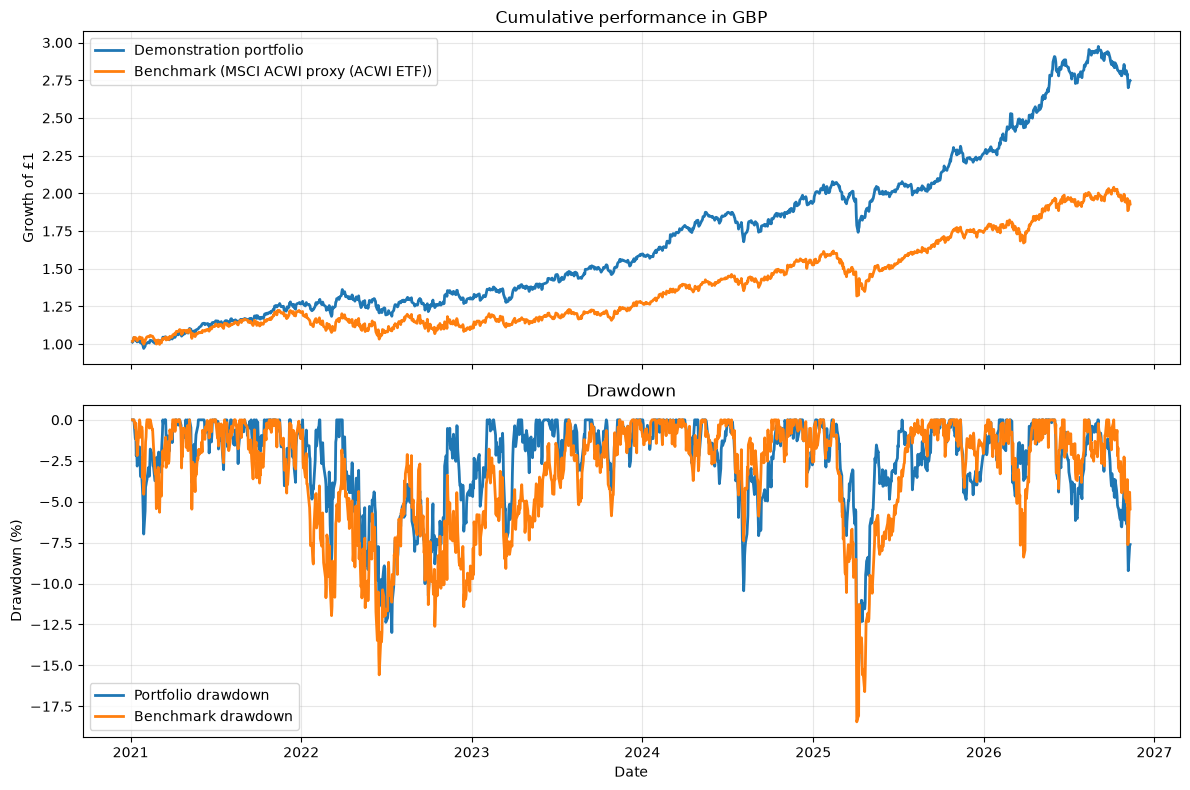

In [38]:
# Portfolio performance and risk summary

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load portfolio weights
# ------------------------------------------------------------

portfolio_weights = pd.read_sql_query(
    """
    SELECT
        instrument_id,
        weight
    FROM portfolio_positions
    WHERE portfolio_id = ?
    """,
    connection,
    params=(PORTFOLIO_ID,),
)

# ------------------------------------------------------------
# 2. Build daily portfolio returns
# ------------------------------------------------------------

portfolio_asset_returns = (
    asset_returns_for_event_study
    .merge(
        portfolio_weights,
        on="instrument_id",
        how="inner",
    )
    .copy()
)

portfolio_asset_returns["weighted_return"] = (
    portfolio_asset_returns["asset_return"]
    * portfolio_asset_returns["weight"]
)

portfolio_daily_returns = (
    portfolio_asset_returns
    .groupby("price_date")
    .agg(
        weighted_return_sum=(
            "weighted_return",
            "sum",
        ),
        available_weight=(
            "weight",
            "sum",
        ),
    )
    .reset_index()
)

portfolio_daily_returns["portfolio_return"] = (
    portfolio_daily_returns["weighted_return_sum"]
    / portfolio_daily_returns["available_weight"]
)

# ------------------------------------------------------------
# 3. Merge portfolio and benchmark returns
# ------------------------------------------------------------

benchmark_daily_returns = (
    benchmark_returns_for_event_study[
        [
            "price_date",
            "benchmark_return",
        ]
    ]
    .copy()
)

portfolio_performance = (
    portfolio_daily_returns[
        [
            "price_date",
            "portfolio_return",
        ]
    ]
    .merge(
        benchmark_daily_returns,
        on="price_date",
        how="inner",
    )
    .sort_values("price_date")
    .reset_index(drop=True)
)

portfolio_performance["portfolio_cumulative"] = (
    1
    + portfolio_performance["portfolio_return"]
).cumprod()

portfolio_performance["benchmark_cumulative"] = (
    1
    + portfolio_performance["benchmark_return"]
).cumprod()

portfolio_performance["portfolio_drawdown"] = (
    portfolio_performance["portfolio_cumulative"]
    / portfolio_performance["portfolio_cumulative"].cummax()
    - 1
)

portfolio_performance["benchmark_drawdown"] = (
    portfolio_performance["benchmark_cumulative"]
    / portfolio_performance["benchmark_cumulative"].cummax()
    - 1
)

# ------------------------------------------------------------
# 4. Calculate performance metrics
# ------------------------------------------------------------

TRADING_DAYS_PER_YEAR = 252

def calculate_metrics(return_series):
    return_series = return_series.dropna()

    cumulative_value = (
        1 + return_series
    ).cumprod()

    total_return = cumulative_value.iloc[-1] - 1

    annualized_return = (
        (1 + total_return)
        ** (
            TRADING_DAYS_PER_YEAR
            / len(return_series)
        )
        - 1
    )

    annualized_volatility = (
        return_series.std(ddof=1)
        * np.sqrt(TRADING_DAYS_PER_YEAR)
    )

    drawdown_series = (
        cumulative_value
        / cumulative_value.cummax()
        - 1
    )

    max_drawdown = drawdown_series.min()

    if annualized_volatility > 0:
        return_risk_ratio = (
            annualized_return
            / annualized_volatility
        )
    else:
        return_risk_ratio = np.nan

    return {
        "total_return": total_return,
        "annualized_return": annualized_return,
        "annualized_volatility": annualized_volatility,
        "max_drawdown": max_drawdown,
        "return_risk_ratio": return_risk_ratio,
        "observations": len(return_series),
    }

portfolio_metrics = calculate_metrics(
    portfolio_performance["portfolio_return"]
)

benchmark_metrics = calculate_metrics(
    portfolio_performance["benchmark_return"]
)

tracking_error = (
    portfolio_performance["portfolio_return"]
    - portfolio_performance["benchmark_return"]
).std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)

return_correlation = (
    portfolio_performance[
        [
            "portfolio_return",
            "benchmark_return",
        ]
    ]
    .corr()
    .loc[
        "portfolio_return",
        "benchmark_return",
    ]
)

performance_summary = pd.DataFrame(
    [
        {
            "series": "Demonstration portfolio",
            **portfolio_metrics,
        },
        {
            "series": f"Benchmark ({benchmark_name})",
            **benchmark_metrics,
        },
    ]
)

performance_summary["tracking_error"] = np.nan
performance_summary.loc[
    performance_summary["series"]
    == "Demonstration portfolio",
    "tracking_error",
] = tracking_error

performance_summary["return_correlation"] = np.nan
performance_summary.loc[
    performance_summary["series"]
    == "Demonstration portfolio",
    "return_correlation",
] = return_correlation

# ------------------------------------------------------------
# 5. Save summary output
# ------------------------------------------------------------

performance_summary.to_csv(
    DATA_DIR / "portfolio_performance_summary.csv",
    index=False,
)

portfolio_performance.to_csv(
    DATA_DIR / "portfolio_daily_performance.csv",
    index=False,
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

display_summary = performance_summary.copy()

percentage_columns = [
    "total_return",
    "annualized_return",
    "annualized_volatility",
    "max_drawdown",
    "tracking_error",
]

for column in percentage_columns:
    display_summary[column] = (
        display_summary[column] * 100
    ).round(2)

display_summary["return_risk_ratio"] = (
    display_summary["return_risk_ratio"]
    .round(3)
)

display_summary["return_correlation"] = (
    display_summary["return_correlation"]
    .round(3)
)

print("Portfolio performance analysis completed.")
print("Benchmark:", benchmark_name)
print(
    "Observation period:",
    portfolio_performance["price_date"].min().date(),
    "to",
    portfolio_performance["price_date"].max().date(),
)
print(
    "Tracking error:",
    round(tracking_error * 100, 2),
    "%",
)
print(
    "Portfolio-benchmark correlation:",
    round(return_correlation, 3),
)

display(
    display_from_one(display_summary)
)

# ------------------------------------------------------------
# 7. Plot cumulative performance and drawdowns
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 8),
    sharex=True,
)

axes[0].plot(
    portfolio_performance["price_date"],
    portfolio_performance["portfolio_cumulative"],
    label="Demonstration portfolio",
    linewidth=2,
)

axes[0].plot(
    portfolio_performance["price_date"],
    portfolio_performance["benchmark_cumulative"],
    label=f"Benchmark ({benchmark_name})",
    linewidth=2,
)

axes[0].set_title(
    "Cumulative performance in GBP"
)

axes[0].set_ylabel("Growth of £1")

axes[0].legend()

axes[0].grid(
    True,
    alpha=0.3,
)

axes[1].plot(
    portfolio_performance["price_date"],
    portfolio_performance["portfolio_drawdown"] * 100,
    label="Portfolio drawdown",
    linewidth=2,
)

axes[1].plot(
    portfolio_performance["price_date"],
    portfolio_performance["benchmark_drawdown"] * 100,
    label="Benchmark drawdown",
    linewidth=2,
)

axes[1].set_title("Drawdown")

axes[1].set_ylabel("Drawdown (%)")

axes[1].set_xlabel("Date")

axes[1].legend()

axes[1].grid(
    True,
    alpha=0.3,
)

plt.tight_layout()

plt.savefig(
    DATA_DIR / "portfolio_performance.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [39]:
# Manager alert and monitoring summary

import numpy as np
import pandas as pd

manager_summary = event_analysis_summary.copy()

manager_summary["absolute_z_score"] = (
    manager_summary["event_z_score"].abs()
)

manager_summary = manager_summary.sort_values(
    by="absolute_z_score",
    ascending=False,
    na_position="last",
).reset_index(drop=True)

manager_summary["watchlist_rank"] = np.nan

valid_z_scores = manager_summary[
    "event_z_score"
].notna()

manager_summary.loc[
    valid_z_scores,
    "watchlist_rank",
] = (
    manager_summary.loc[
        valid_z_scores,
        "absolute_z_score",
    ]
    .rank(
        method="first",
        ascending=False,
    )
)

def classify_priority(row):
    if row["signal"] in [
        "Positive alert",
        "Negative alert",
    ]:
        return "High"

    if (
        pd.notna(row["event_z_score"])
        and abs(row["event_z_score"]) >= 1.0
    ):
        return "Medium"

    return "Low"

def define_manager_action(row):
    if row["signal"] == "Negative alert":
        if row["thesis_match"] == 1:
            return (
                "Review the investment thesis and assess "
                "whether position sizing should be reconsidered."
            )

        return (
            "Investigate the negative market reaction and "
            "assess whether the investment thesis is affected."
        )

    if row["signal"] == "Positive alert":
        if row["thesis_match"] == 1:
            return (
                "Review whether the positive reaction confirms "
                "the investment thesis."
            )

        return (
            "Monitor the positive reaction; no automatic "
            "portfolio action is recommended."
        )

    if (
        pd.notna(row["event_z_score"])
        and abs(row["event_z_score"]) >= 1.0
    ):
        return (
            "Keep on the monitoring watchlist; the reaction "
            "is notable but below the alert threshold."
        )

    return (
        "No escalation. Retain the event in routine monitoring."
    )

manager_summary["priority"] = (
    manager_summary.apply(
        classify_priority,
        axis=1,
    )
)

manager_summary["manager_action"] = (
    manager_summary.apply(
        define_manager_action,
        axis=1,
    )
)

manager_summary["thesis_status"] = (
    manager_summary["thesis_match"]
    .map(
        {
            0: "No explicit thesis-risk match",
            1: "Explicit thesis-risk match",
        }
    )
)

manager_summary["monitoring_status"] = (
    manager_summary["priority"]
    .map(
        {
            "High": "Escalate",
            "Medium": "Watchlist",
            "Low": "Routine monitoring",
        }
    )
)

manager_summary = manager_summary[
    [
        "event_date",
        "ticker",
        "company_name",
        "event_type",
        "headline",
        "event_z_score",
        "cumulative_abnormal_return",
        "portfolio_impact",
        "signal",
        "priority",
        "monitoring_status",
        "thesis_status",
        "manager_action",
    ]
].copy()

manager_summary.to_csv(
    DATA_DIR / "manager_alert_summary.csv",
    index=False,
)

high_priority_count = int(
    (manager_summary["priority"] == "High").sum()
)

watchlist_count = int(
    (manager_summary["priority"] == "Medium").sum()
)

print("Manager alert summary created.")
print("High-priority alerts:", high_priority_count)
print("Watchlist events:", watchlist_count)
print(
    "Routine-monitoring events:",
    int(
        (manager_summary["priority"] == "Low").sum()
    ),
)

display(
    display_from_one(manager_summary)
)

Manager alert summary created.
High-priority alerts: 1
Watchlist events: 2
Routine-monitoring events: 9


,event_date,ticker,company_name,event_type,headline,event_z_score,cumulative_abnormal_return,portfolio_impact,signal,priority,monitoring_status,thesis_status,manager_action
row_id,,,,,,,,,,,,,
1,2026-10-05,SCHN.PA,Schneider Electric,M&A announcement,"Schneider Electric to acquire PTC, creating th...",-5.902010,-0.152839,-0.010189,Negative alert,High,Escalate,No explicit thesis-risk match,Investigate the negative market reaction and a...
2,2026-10-19,ISP.MI,Intesa Sanpaolo,Corporate finance / M&A,Board of Directors Approves Capital Increase F...,-1.689636,-0.019060,-0.001271,No alert,Medium,Watchlist,No explicit thesis-risk match,Keep on the monitoring watchlist; the reaction...
3,2026-10-30,DBSM.SI,DBS Group,Sustainable-finance partnership,DBS Announces Memorandum of Understanding on S...,-1.085188,-0.050185,-0.003346,No alert,Medium,Watchlist,No explicit thesis-risk match,Keep on the monitoring watchlist; the reaction...
4,2026-10-23,000660.KS,SK Hynix,Strategic / capital markets event,Solidigm to Discontinue Review of Potential IP...,0.720512,0.072349,0.004823,No alert,Low,Routine monitoring,No explicit thesis-risk match,No escalation. Retain the event in routine mon...
5,2026-10-09,EQNR.OL,Equinor,Strategic partnership,Equinor and Shell Partner on Bay du Nord,0.697252,0.024103,0.001607,No alert,Low,Routine monitoring,No explicit thesis-risk match,No escalation. Retain the event in routine mon...
6,2026-10-06,DELL.N,Dell Technologies,Corporate technology announcement,Dell Technologies Turns Enterprise Data into T...,0.544228,0.019180,0.001279,No alert,Low,Routine monitoring,No explicit thesis-risk match,No escalation. Retain the event in routine mon...
7,2026-10-01,HSY.N,Hershey,Management appointment,The Hershey Company Names Amanda Almond Presid...,0.505209,-0.020417,-0.001361,No alert,Low,Routine monitoring,No explicit thesis-risk match,No escalation. Retain the event in routine mon...
8,2026-10-06,7974.T,Nintendo,Product event,Nintendo Switch 2 Japanese-Language System Bun...,0.463354,-0.001061,-0.000071,No alert,Low,Routine monitoring,No explicit thesis-risk match,No escalation. Retain the event in routine mon...
9,2026-10-06,CVX.N,Chevron,Asset divestiture,Chevron to Divest Its Ownership Interests in H...,0.419210,0.019179,0.001279,No alert,Low,Routine monitoring,No explicit thesis-risk match,No escalation. Retain the event in routine mon...


Pipeline validation completed successfully.


,check,status,value
row_id,,,
1,Portfolio holdings,True,15
2,Portfolio weights sum to one,True,1.0
3,Verified events,True,12
4,Event-instrument links,True,12
5,Thesis-match records,True,12
6,Event-analysis records,True,12
7,Missing converted asset prices,True,0
8,Missing converted benchmark prices,True,0
9,Events with official domains,True,True


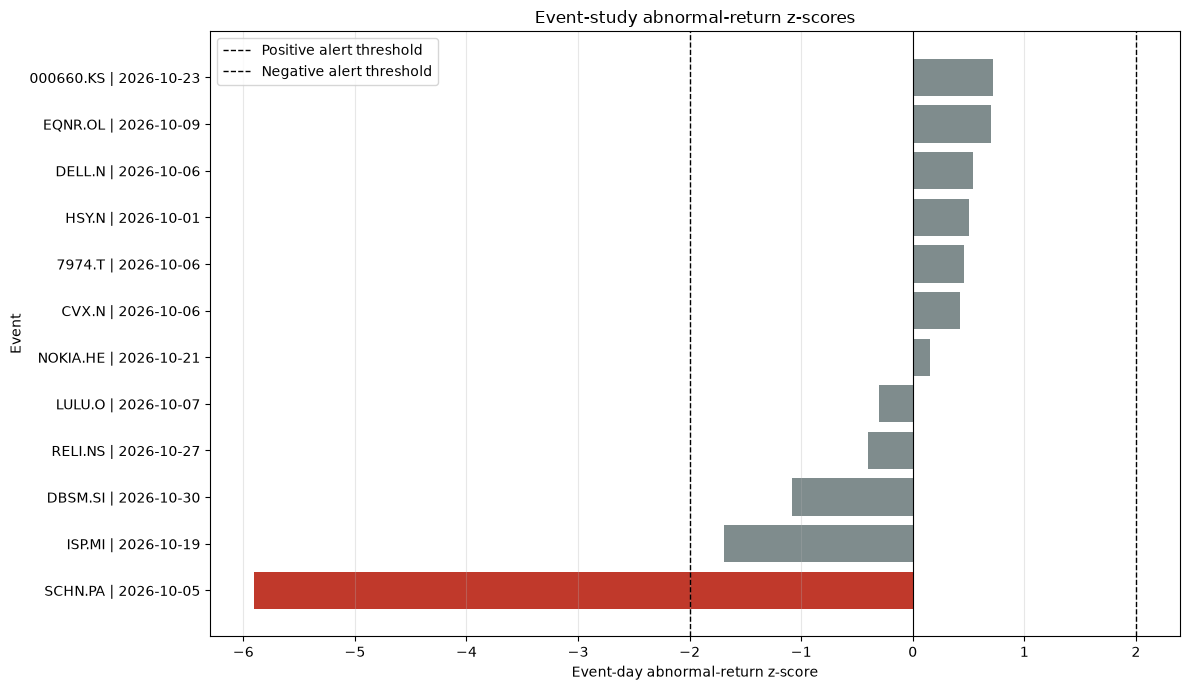

,artifact,path
row_id,,
1,Verified event snapshot,data/events_snapshot.csv
2,Portfolio performance summary,data/portfolio_performance_summary.csv
3,Daily portfolio performance,data/portfolio_daily_performance.csv
4,Manager alert summary,data/manager_alert_summary.csv
5,Pipeline validation summary,data/pipeline_validation_summary.csv
6,Portfolio performance chart,data/portfolio_performance.png
7,Event z-score chart,data/event_z_score_chart.png


In [40]:
# Final validation and event-study visualization

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Validate database outputs
# ------------------------------------------------------------

database_counts = pd.read_sql_query(
    """
    SELECT 'instruments' AS table_name, COUNT(*) AS row_count
    FROM instruments

    UNION ALL

    SELECT 'portfolio_positions', COUNT(*)
    FROM portfolio_positions

    UNION ALL

    SELECT 'market_prices', COUNT(*)
    FROM market_prices

    UNION ALL

    SELECT 'fx_rates', COUNT(*)
    FROM fx_rates

    UNION ALL

    SELECT 'benchmarks', COUNT(*)
    FROM benchmarks

    UNION ALL

    SELECT 'events', COUNT(*)
    FROM events

    UNION ALL

    SELECT 'event_instruments', COUNT(*)
    FROM event_instruments

    UNION ALL

    SELECT 'event_thesis_matches', COUNT(*)
    FROM event_thesis_matches

    UNION ALL

    SELECT 'event_analysis', COUNT(*)
    FROM event_analysis
    """,
    connection,
)

database_counts["row_count"] = (
    database_counts["row_count"].astype(int)
)

counts = dict(
    zip(
        database_counts["table_name"],
        database_counts["row_count"],
    )
)

validation_results = [
    {
        "check": "Portfolio holdings",
        "status": counts["instruments"] == 15,
        "value": counts["instruments"],
    },
    {
        "check": "Portfolio weights sum to one",
        "status": bool(
            np.isclose(
                portfolio["weight"].sum(),
                1.0,
            )
        ),
        "value": portfolio["weight"].sum(),
    },
    {
        "check": "Verified events",
        "status": counts["events"] == 12,
        "value": counts["events"],
    },
    {
        "check": "Event-instrument links",
        "status": counts["event_instruments"] == 12,
        "value": counts["event_instruments"],
    },
    {
        "check": "Thesis-match records",
        "status": counts["event_thesis_matches"] == 12,
        "value": counts["event_thesis_matches"],
    },
    {
        "check": "Event-analysis records",
        "status": counts["event_analysis"] == 12,
        "value": counts["event_analysis"],
    },
    {
        "check": "Missing converted asset prices",
        "status": missing_asset_prices == 0,
        "value": missing_asset_prices,
    },
    {
        "check": "Missing converted benchmark prices",
        "status": missing_benchmark_prices == 0,
        "value": missing_benchmark_prices,
    },
    {
        "check": "Events with official domains",
        "status": bool(
            events_snapshot["source_url"]
            .apply(is_official_domain)
            .all()
        ),
        "value": "True",
    },
]

validation_summary = pd.DataFrame(
    validation_results
)

validation_summary.to_csv(
    DATA_DIR / "pipeline_validation_summary.csv",
    index=False,
)

assert validation_summary["status"].all()

print("Pipeline validation completed successfully.")
display(
    display_from_one(validation_summary)
)

# ------------------------------------------------------------
# 2. Event z-score chart
# ------------------------------------------------------------

event_plot_data = manager_summary.copy()

event_plot_data = event_plot_data.dropna(
    subset=["event_z_score"]
)

event_plot_data = event_plot_data.sort_values(
    "event_z_score"
)

colors = event_plot_data["signal"].map(
    {
        "Negative alert": "#C0392B",
        "Positive alert": "#2E8B57",
        "No alert": "#7F8C8D",
    }
).fillna("#7F8C8D")

labels = (
    event_plot_data["ticker"]
    + " | "
    + event_plot_data["event_date"].astype(str)
)

fig, ax = plt.subplots(
    figsize=(12, 7)
)

ax.barh(
    labels,
    event_plot_data["event_z_score"],
    color=colors,
)

ax.axvline(
    z_score_threshold,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Positive alert threshold",
)

ax.axvline(
    -z_score_threshold,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Negative alert threshold",
)

ax.axvline(
    0,
    color="black",
    linewidth=0.8,
)

ax.set_title(
    "Event-study abnormal-return z-scores"
)

ax.set_xlabel(
    "Event-day abnormal-return z-score"
)

ax.set_ylabel(
    "Event"
)

ax.legend()

ax.grid(
    axis="x",
    alpha=0.3,
)

plt.tight_layout()

plt.savefig(
    DATA_DIR / "event_z_score_chart.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 3. Final artifact summary
# ------------------------------------------------------------

artifact_summary = pd.DataFrame(
    [
        {
            "artifact": "Verified event snapshot",
            "path": str(EVENT_SNAPSHOT_PATH),
        },
        {
            "artifact": "Portfolio performance summary",
            "path": str(
                DATA_DIR
                / "portfolio_performance_summary.csv"
            ),
        },
        {
            "artifact": "Daily portfolio performance",
            "path": str(
                DATA_DIR
                / "portfolio_daily_performance.csv"
            ),
        },
        {
            "artifact": "Manager alert summary",
            "path": str(
                DATA_DIR
                / "manager_alert_summary.csv"
            ),
        },
        {
            "artifact": "Pipeline validation summary",
            "path": str(
                DATA_DIR
                / "pipeline_validation_summary.csv"
            ),
        },
        {
            "artifact": "Portfolio performance chart",
            "path": str(
                DATA_DIR
                / "portfolio_performance.png"
            ),
        },
        {
            "artifact": "Event z-score chart",
            "path": str(
                DATA_DIR
                / "event_z_score_chart.png"
            ),
        },
    ]
)

display(
    display_from_one(artifact_summary)
)